# 04 — Cluster Profiling, Model Evaluation and Recommendation
## OSMI 2016: Workplace Support, Psychological Safety, and Disclosure Climate

### Objective
Notebook 03 fitted four clustering families and declared at most one representative configuration per family, deferring the choice between families. This notebook completes the project by:

1. **Profiling** every candidate partition: who is in each cluster, and which workplace-climate responses distinguish it.
2. **Evaluating** the candidates on common footing: native diagnostics recapped but not cross-ranked; stability, separation and balance computed identically for every family.
3. **Recommending** a model through explicit gates, a transparent multi-criteria scorecard and a weight-sensitivity analysis, with the strength of the evidence stated plainly.
4. **Describing** the recommended segmentation for stakeholders, with its limitations.

### Evaluation principles (carried from Notebooks 01 and 03)
- Native metrics (K-Modes cost, MCA-space silhouette, cophenetic correlation, DBCV) belong to their own representation and are **not compared across families**.
- Cross-family comparison uses only quantities defined identically for all partitions: resampling stability, worst-cluster stability, Gower silhouette, response-profile separation (bias-corrected Cramér's V on the 15 clustering items), coverage and balance.
- There are no ground-truth labels. A good partition must be stable, non-degenerate and interpretable; strong separation is not assumed.
- Clusters describe **aggregate response patterns**, not diagnoses, individual risk or employee suitability. Diagnosis, treatment and suspected-condition variables are never used. Demographic and contextual variables, if available, are used only for cautious *descriptive* profiling after the clusters are formed.

### Decision rule (fixed before looking at results)
A family is **eligible** only if it passes five gates: a representative was declared; the smallest cluster holds at least 5% of respondents; at least 80% of respondents are clustered; mean resampling ARI ≥ 0.60; and the worst cluster's mean Jaccard stability ≥ 0.60. Eligible families are ranked on five equally weighted criteria; differences smaller than a declared *material margin* count as ties, the winner's raw margins over the runner-up are reported, and the weights are then perturbed to test whether the ranking depends on them. If no family passes every gate, the notebook says so and issues only a **provisional, exploratory** recommendation.

## 1. Imports, configuration and paths

In [1]:
from __future__ import annotations

import json
import math
import re
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from hdbscan import HDBSCAN
from IPython.display import Markdown
from kmodes.kmodes import KModes
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_samples,
    silhouette_score,
)

RANDOM_STATE = 42

# Resampling stability (identical subsamples are reused for every family -> paired comparison)
N_RESAMPLES = 30
SUBSAMPLE_FRACTION = 0.80

# Gates (fixed before results are inspected)
MIN_CLUSTER_SHARE = 0.05
GATE_MIN_COVERAGE = 0.80
GATE_ARI_FLOOR = 0.60
GATE_JACCARD_FLOOR = 0.60          # Hennig's guide: < 0.60 = unstable cluster

# Scorecard: equal weights over these criteria (all "higher is better")
CRITERIA = {
    "resampling_ari_mean": "Resampling stability (ARI)",
    "jaccard_worst_cluster": "Worst-cluster stability (Jaccard)",
    "gower_silhouette": "Gower silhouette",
    "profile_separation": "Response-profile separation (mean V)",
    "coverage": "Coverage",
}
N_WEIGHT_DRAWS = 5000

# Differences smaller than these margins are treated as practical ties (declared up front; judgement calls).
MATERIAL_MARGIN = {
    "resampling_ari_mean": 0.05,
    "jaccard_worst_cluster": 0.05,
    "gower_silhouette": 0.03,
    "profile_separation": 0.05,
    "coverage": 0.02,
}

# Profiling
MIN_CELL_FOR_DISTINCTIVE = 15      # minimum respondents in a cluster/response cell to be called distinctive
UNCERTAIN_PATTERN = r"don'?t know|do not know|not sure|unsure|maybe|neither|unknown"

# Optional analyst-supplied names, e.g. {("K-Modes", 0): "Supported and open"}.
# Left empty on purpose: names are an interpretive act and should be written after reading the profiles.
CLUSTER_NAMES: dict[tuple[str, int], str] = {}

FAMILY_COLOURS = {
    "K-Modes": "#4c72b0", "MCA + K-Means": "#dd8452",
    "Agglomerative": "#55a868", "HDBSCAN": "#c44e52",
}
FAMILY_ORDER = list(FAMILY_COLOURS)
CLUSTER_CMAP = plt.get_cmap("tab10")

HERE = Path.cwd().resolve()
PROJECT_ROOT = HERE.parent if HERE.name == "notebooks" else HERE
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELLING_DIR = PROJECT_ROOT / "reports" / "results" / "data_modelling"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results" / "model_evaluation"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "model_evaluation"
for directory in (RESULTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "axes.grid": True,
        "grid.alpha": 0.2,
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False
    }
)


def save_figure(fig, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=300, bbox_inches="tight")
    plt.show()


def cname(model_key: str, label: int) -> str:
    return CLUSTER_NAMES.get((model_key, int(label)), f"C{int(label)}")

## 2. Load and validate the Notebook 02 and 03 artefacts

The Notebook 03 labels are checked against the Notebook 02 row structure and against the diagnostics Notebook 03 itself recorded (cluster counts, smallest cluster, coverage). This guards against comparing labels that belong to a different run or row order.

In [2]:
NB2_FILES = {
    "kmodes": PROCESSED_DIR / "osmi_2016_kmodes_input.csv",
    "mca_indicator": PROCESSED_DIR / "osmi_2016_mca_indicator_matrix.csv",
    "gower": PROCESSED_DIR / "osmi_2016_gower_dissimilarity.npy",
    "row_mapping": PROCESSED_DIR / "osmi_2016_model_row_mapping.csv",
    "preparation_metadata": PROCESSED_DIR / "osmi_2016_preparation_metadata.json",
}
NB3_FILES = {
    "labels": MODELLING_DIR / "osmi_2016_candidate_cluster_labels.csv",
    "comparison": MODELLING_DIR / "osmi_2016_model_comparison.csv",
    "grid": MODELLING_DIR / "osmi_2016_model_grid_search.csv",
    "selection": MODELLING_DIR / "osmi_2016_selected_model.json",
    "metadata": MODELLING_DIR / "osmi_2016_modelling_metadata.json",
}
missing = [str(p) for p in {**NB2_FILES, **NB3_FILES}.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Run Notebooks 02 and 03 first. Missing: " + ", ".join(missing))

X_kmodes = pd.read_csv(NB2_FILES["kmodes"], dtype="string")
X_mca_indicator = pd.read_csv(NB2_FILES["mca_indicator"])
D_gower = np.asarray(np.load(NB2_FILES["gower"], allow_pickle=False), dtype=np.float64)
D_gower = np.clip((D_gower + D_gower.T) / 2.0, 0.0, 1.0)
np.fill_diagonal(D_gower, 0.0)
row_mapping = pd.read_csv(NB2_FILES["row_mapping"])
with NB2_FILES["preparation_metadata"].open(encoding="utf-8") as f:
    prep_meta = json.load(f)

candidate_labels = pd.read_csv(NB3_FILES["labels"])
model_comparison = pd.read_csv(NB3_FILES["comparison"])
grid_results = pd.read_csv(NB3_FILES["grid"])
with NB3_FILES["selection"].open(encoding="utf-8") as f:
    selection = json.load(f)
with NB3_FILES["metadata"].open(encoding="utf-8") as f:
    modelling_meta = json.load(f)

PRIMARY_FEATURES = prep_meta["primary_features"]
FEATURES_BY_DOMAIN = prep_meta["feature_domains"]
FEATURE_DOMAIN = {f: d for d, fs in FEATURES_BY_DOMAIN.items() for f in fs}
N = int(prep_meta["eligible_cohort_size"])
Q = int(prep_meta["primary_feature_count"])
MIN_CLUSTER_SIZE = int(math.ceil(MIN_CLUSTER_SHARE * N))

assert N == 1131 and Q == 15 and len(PRIMARY_FEATURES) == 15
assert X_kmodes.shape == (N, Q) and list(X_kmodes.columns) == PRIMARY_FEATURES
assert X_mca_indicator.shape[0] == N and D_gower.shape == (N, N)
assert np.array_equal(row_mapping["model_row_index"].to_numpy(), np.arange(N))
assert selection["selection_status"] == "deferred_to_notebook_04", \
    "Notebook 03 should have deferred the final family selection."
assert modelling_meta["random_state"] is not None

# Wide label dictionary: model_key -> array indexed by model_row_index
partitions = {}
for key, grp in candidate_labels.groupby("model_key"):
    grp = grp.sort_values("model_row_index")
    assert len(grp) == N and np.array_equal(grp["model_row_index"].to_numpy(), np.arange(N)), key
    partitions[key] = grp["cluster_label"].to_numpy(dtype=int)
FAMILIES = [k for k in FAMILY_ORDER if k in partitions]
NO_REPRESENTATIVE = [k for k in FAMILY_ORDER if k not in partitions]
REPRESENTATIVES = selection["representative_configurations"]


def summarise_labels(labels):
    assigned = labels[labels != -1]
    counts = pd.Series(assigned).value_counts()
    return {
        "n_clusters": int(counts.size),
        "smallest": int(counts.min()),
        "coverage": float((labels != -1).mean())
    }


# Cross-check labels against what Notebook 03 recorded for the same representatives
for _, row in model_comparison.iterrows():
    s = summarise_labels(partitions[row["model_key"]])
    assert s["n_clusters"] == int(row["n_clusters"]), f"{row['model_key']}: cluster count differs from Notebook 03"
    assert s["smallest"] == int(row["smallest_cluster_size"]), f"{row['model_key']}: smallest cluster differs"
    assert np.isclose(s["coverage"], float(row["coverage"])), f"{row['model_key']}: coverage differs"

print(f"Respondents: {N:,}; clustering features: {Q}; minimum admissible cluster: {MIN_CLUSTER_SIZE}")
print(f"Candidate families with a representative: {FAMILIES}")
print(f"Families without a qualifying representative in Notebook 03: {NO_REPRESENTATIVE or 'none'}")
display(pd.DataFrame(REPRESENTATIVES).T.dropna(axis=1, how="all"))

Respondents: 1,131; clustering features: 15; minimum admissible cluster: 57
Candidate families with a representative: ['K-Modes', 'MCA + K-Means', 'Agglomerative']
Families without a qualifying representative in Notebook 03: ['HDBSCAN']


,k,seed,n_init_per_repeat,cost_elbow_k,selection_rule,selection_tier,n_mca_dimensions,linkage,linkage_role,k_requested,k_actual,average_linkage_admissible,status,admissibility_criteria,closest_attempt_not_exported
K-Modes,2,2042,5,3,"admissible, stable first; highest Gower silhou...",admissible and stable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MCA + K-Means,2,4045,NaN,NaN,"admissible, stable first; highest MCA silhouet...",admissible and stable,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Agglomerative,NaN,NaN,NaN,NaN,admissible (min cluster size); average linkage...,FALLBACK: no admissible average-linkage cut; b...,NaN,weighted,sensitivity,2,2,False,NaN,NaN,NaN
HDBSCAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no qualifying representative,"{'min_cluster_size': 57, 'min_coverage': 0.5, ...","{'config_key': 'eom_mcs10_ms3', 'coverage': 0...."


## 3. Candidate overview: sizes, balance and coverage

Balance is the normalised Shannon entropy of the cluster-size distribution (1 = equal-sized clusters, near 0 = one dominant cluster). It is reported because a partition dominated by one giant cluster plus fragments is rarely a useful segmentation, however well it scores on a distance-based index.

,n_clusters,cluster_sizes,n_noise,coverage,smallest_cluster,largest_share,balance
model_key,,,,,,,
K-Modes,2,"{0: 621, 1: 510}",0,1.0,510,0.549,0.993
MCA + K-Means,2,"{0: 607, 1: 524}",0,1.0,524,0.537,0.996
Agglomerative,2,"{0: 57, 1: 1074}",0,1.0,57,0.950,0.288


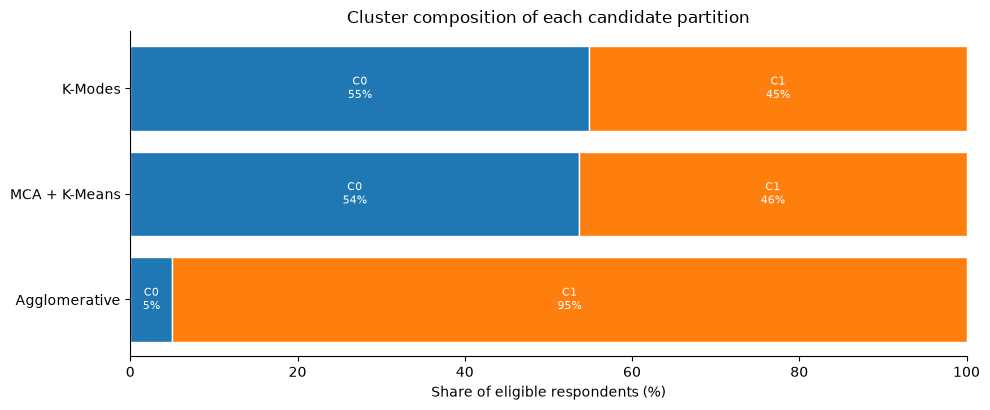

In [3]:
def balance(labels):
    counts = pd.Series(labels[labels != -1]).value_counts().to_numpy(dtype=float)
    if counts.size < 2:
        return np.nan
    p = counts / counts.sum()
    return float(-(p * np.log(p)).sum() / np.log(counts.size))


overview_rows = []
for key in FAMILIES:
    labels = partitions[key]
    counts = pd.Series(labels[labels != -1]).value_counts().sort_index()
    overview_rows.append({
        "model_key": key,
        "n_clusters": int(counts.size),
        "cluster_sizes": counts.to_dict(),
        "n_noise": int((labels == -1).sum()),
        "coverage": float((labels != -1).mean()),
        "smallest_cluster": int(counts.min()),
        "largest_share": float(counts.max() / counts.sum()),
        "balance": balance(labels),
    })
overview = pd.DataFrame(overview_rows).set_index("model_key")
display(overview.round(3))

fig, ax = plt.subplots(figsize=(10, 0.9 * len(FAMILIES) + 1.5))
for y, key in enumerate(FAMILIES):
    labels = partitions[key]
    left = 0.0
    for c in sorted(np.unique(labels[labels != -1])):
        w = (labels == c).mean() * 100
        ax.barh(
            y,
            w,
            left=left,
            color=CLUSTER_CMAP(int(c) % 10),
            edgecolor="white"
        )
        ax.text(
            left + w / 2,
            y,
            f"{cname(key, c)}\n{w:.0f}%",
            ha="center",
            va="center",
            fontsize=8,
            color="white"
        )
        left += w
    if (labels == -1).any():
        w = (labels == -1).mean() * 100
        ax.barh(
            y,
            w,
            left=left,
            color="#bbbbbb",
            edgecolor="white"
        )
        ax.text(
            left + w / 2,
            y,
            f"noise\n{w:.0f}%",
            ha="center",
            va="center",
            fontsize=8
        )
ax.set_yticks(range(len(FAMILIES)), FAMILIES)
ax.invert_yaxis()
ax.set(
    xlim=(0, 100),
    xlabel="Share of eligible respondents (%)",
    title="Cluster composition of each candidate partition"
)
ax.grid(False)
save_figure(fig, "candidate_cluster_composition.png")

## 4. Cluster profiling

### 4.1 Which items define the clusters? (bias-corrected Cramér's V)
For each family and each of the 15 clustering items, Cramér's V measures the association between the item's response categories and cluster membership (0 = none, 1 = perfect), corrected for the upward small-sample bias of the raw statistic (Bergsma, 2013). Noise respondents are excluded. Because the clusters were built from these same items, V is a *descriptive* measure of how much each item contributes to the partition, not a significance test. It is computed identically for every family and therefore also serves as the cross-family **profile separation** criterion.

model_key,K-Modes,MCA + K-Means,Agglomerative
domain,,,
disclosure_career_climate,0.499,0.445,0.219
employer_support,0.240,0.343,0.111
psychological_safety,0.434,0.514,0.179


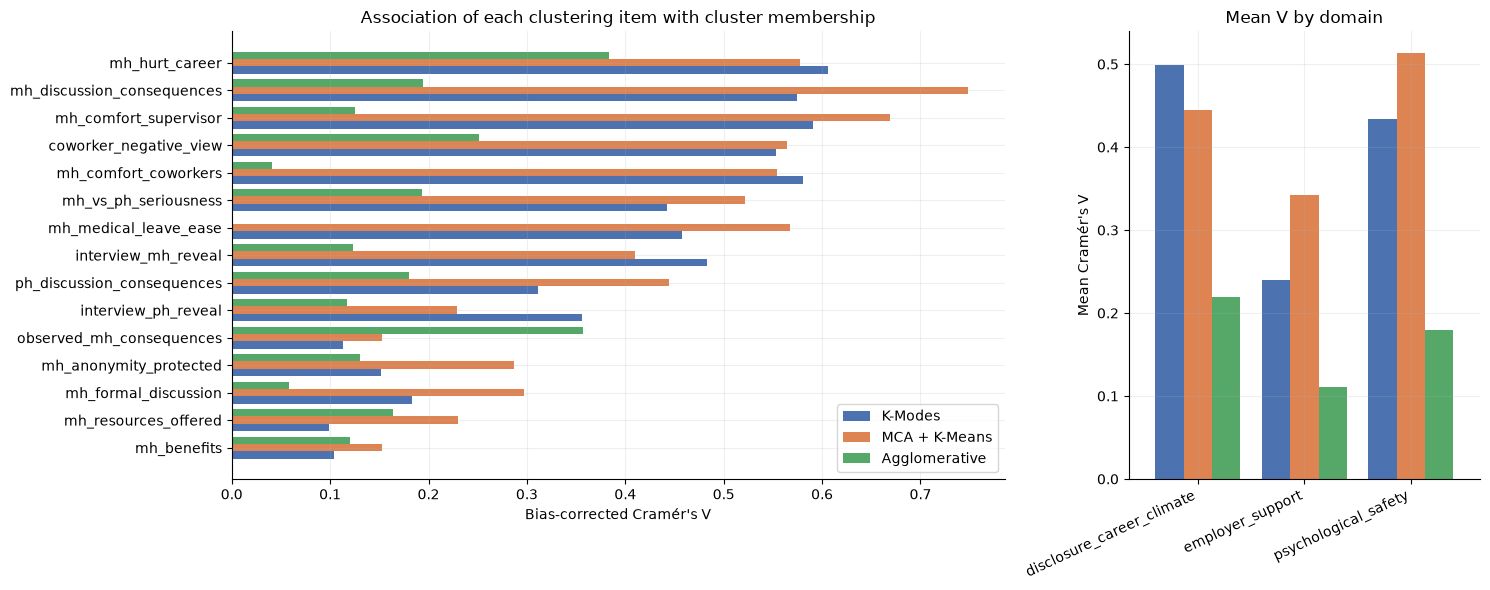

In [4]:
def cramers_v_corrected(ct: np.ndarray) -> float:
    n = ct.sum()
    r, k = ct.shape
    if r < 2 or k < 2 or n < 2:
        return np.nan
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    phi2 = chi2 / n
    phi2c = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2c / denom)) if denom > 0 else np.nan


def clustered_frame(labels):
    mask = labels != -1
    frame = X_kmodes.loc[mask].copy()
    frame["cluster"] = labels[mask]
    return frame


association_rows = []
for key in FAMILIES:
    frame = clustered_frame(partitions[key])
    for f in PRIMARY_FEATURES:
        ct = pd.crosstab(frame[f], frame["cluster"]).to_numpy()
        association_rows.append(
            {
                "model_key": key,
                "feature": f,
                "domain": FEATURE_DOMAIN[f],
                "cramers_v": cramers_v_corrected(ct)
            }
        )
association = pd.DataFrame(association_rows)
profile_separation = association.groupby("model_key")["cramers_v"].mean()
domain_separation = association.pivot_table(
    index="domain",
    columns="model_key",
    values="cramers_v",
    aggfunc="mean"
)[FAMILIES]
display(domain_separation.round(3))

order = (association.groupby("feature")["cramers_v"].mean().sort_values().index)
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    gridspec_kw={"width_ratios": [2.2, 1]}
)
height = 0.8 / len(FAMILIES)
for i, key in enumerate(FAMILIES):
    sub = association[association["model_key"] == key].set_index("feature").loc[order]
    axes[0].barh(
        np.arange(len(order)) + i * height,
        sub["cramers_v"], height=height,
        color=FAMILY_COLOURS[key], label=key
    )
axes[0].set_yticks(np.arange(len(order)) + height * (len(FAMILIES) - 1) / 2, order)
axes[0].set(
    xlabel="Bias-corrected Cramér's V",
    title="Association of each clustering item with cluster membership"
)
axes[0].legend(loc="lower right")
domain_separation.plot.bar(
    ax=axes[1],
    color=[FAMILY_COLOURS[k] for k in FAMILIES],
    legend=False, width=0.8
)
axes[1].set(
    title="Mean V by domain",
    ylabel="Mean Cramér's V",
    xlabel=""
)
plt.setp(
    axes[1].get_xticklabels(),
    rotation=25, ha="right"
)
save_figure(fig, "item_association_cramers_v.png")

### 4.2 Response profiles for every candidate
For each cluster and response category the table records the cluster share, the **lift** (cluster share ÷ overall share), the percentage-point difference from all other respondents, and the Pearson standardised residual from the item × cluster table. Heatmaps show log₂ lift (red = over-represented in the cluster, blue = under-represented) annotated with the within-cluster share.

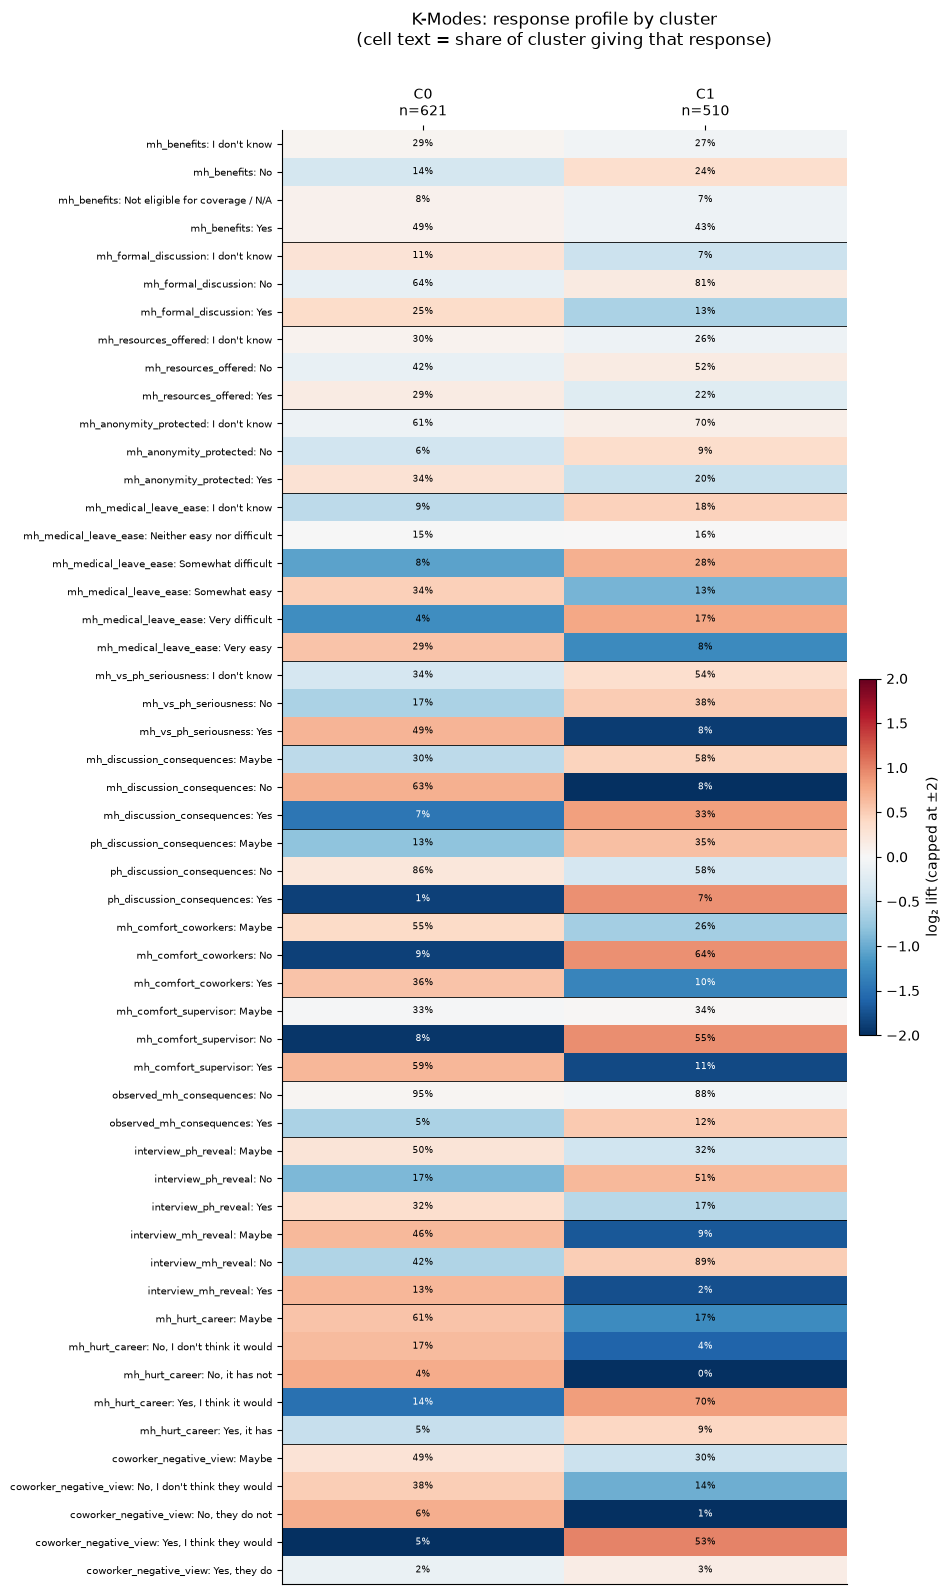

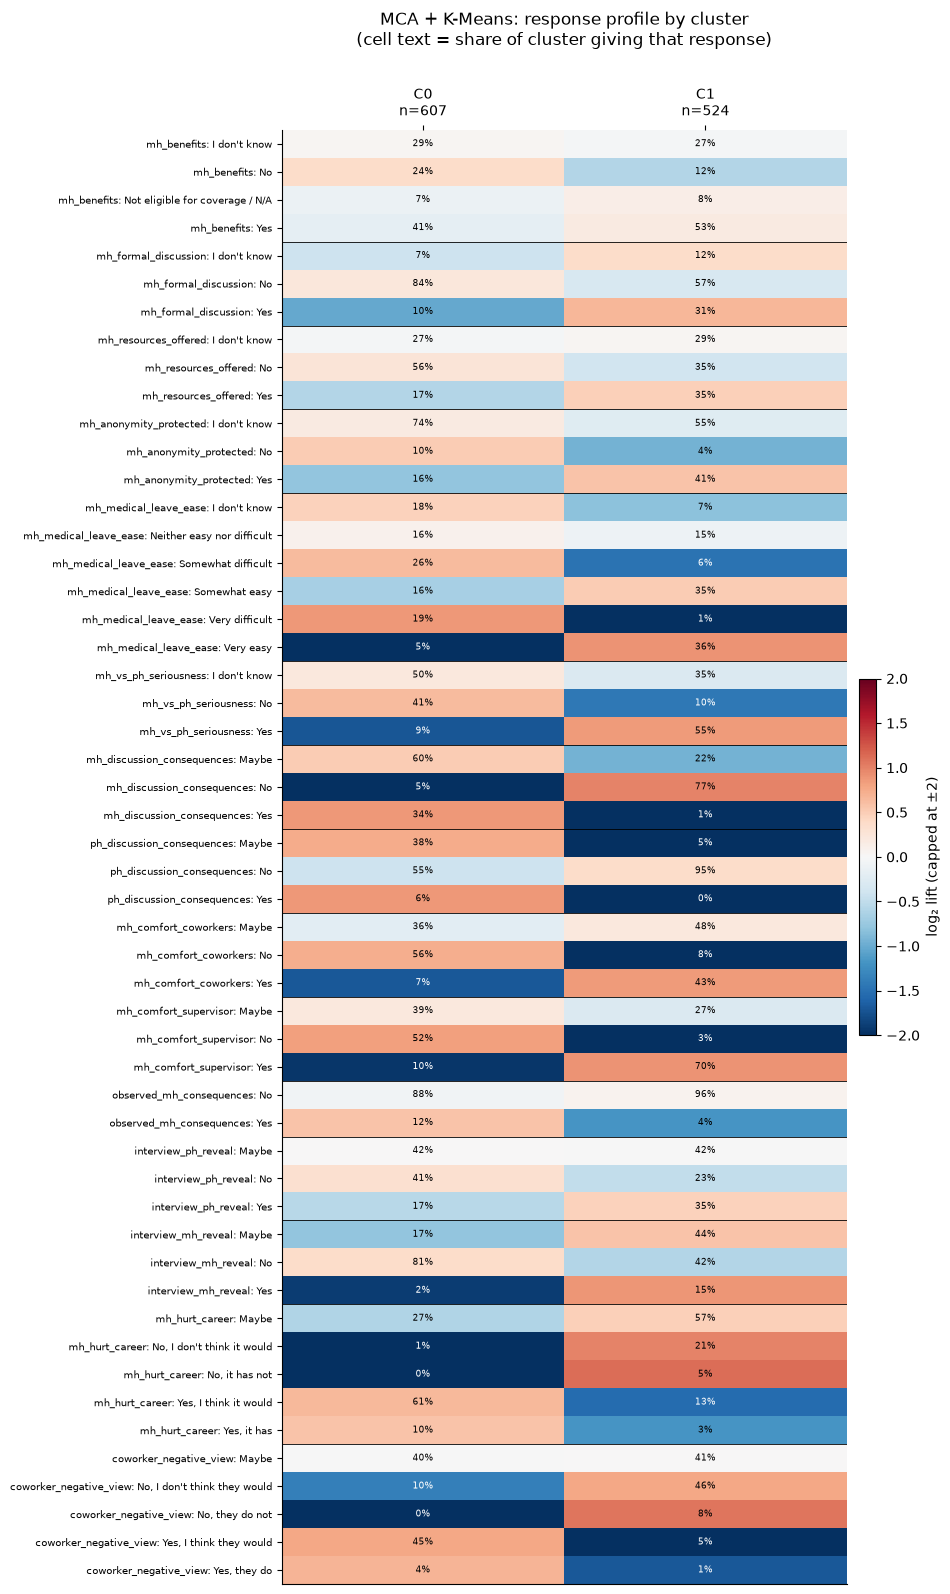

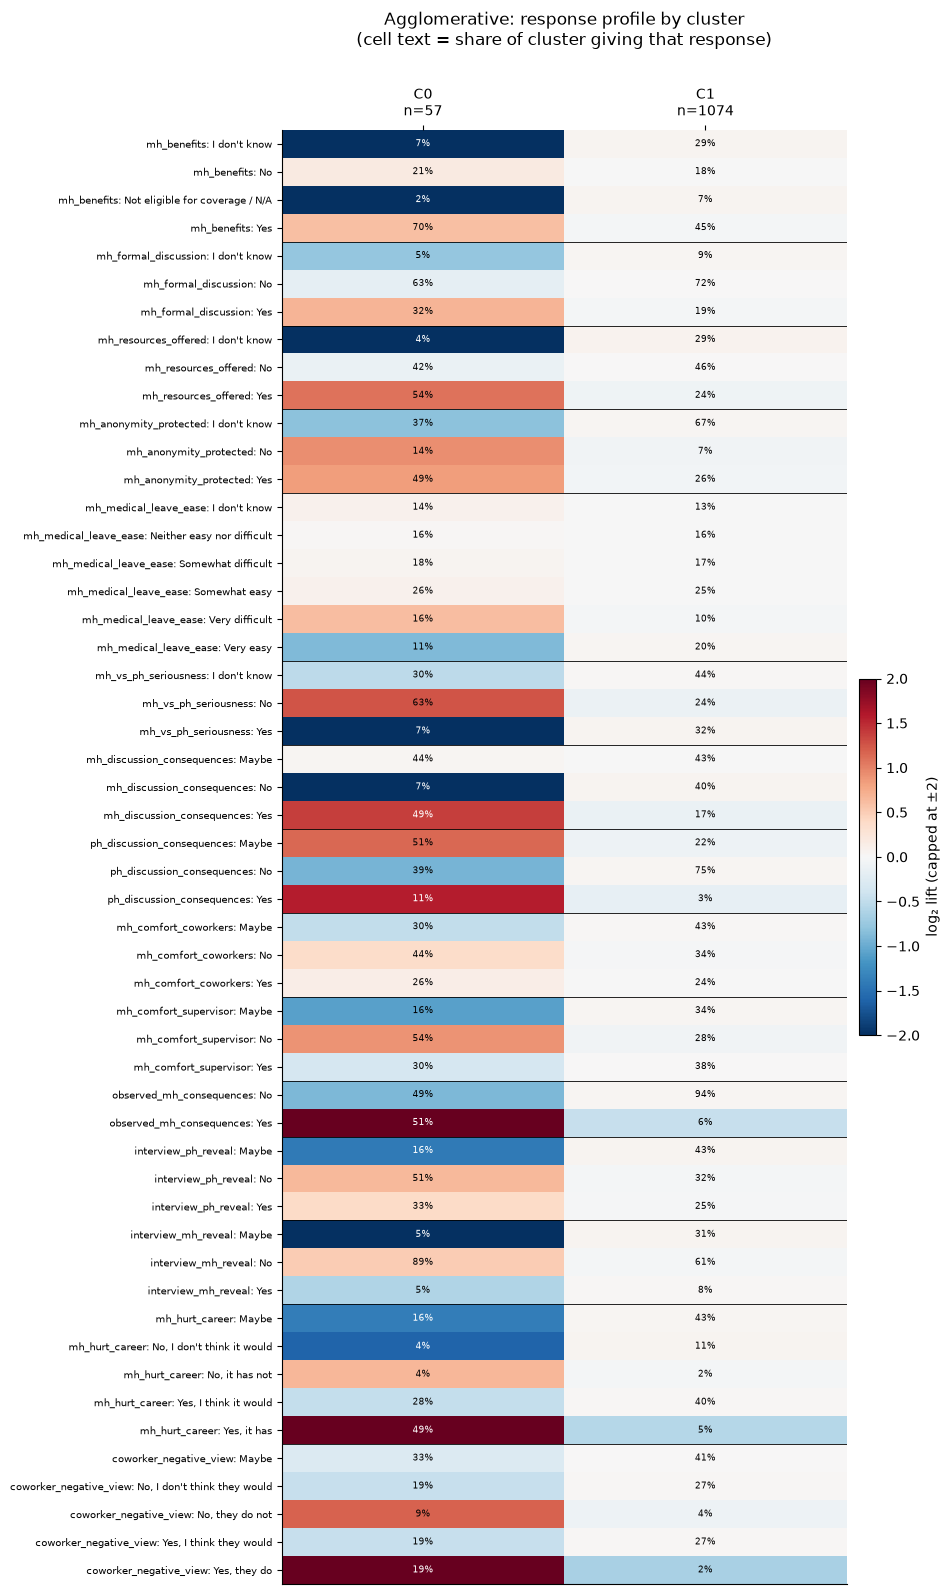

In [5]:
def build_profile(model_key, labels) -> pd.DataFrame:
    frame = clustered_frame(labels)
    n_total = len(frame)
    sizes = frame["cluster"].value_counts()
    rows = []
    for f in PRIMARY_FEATURES:
        ct = pd.crosstab(frame[f], frame["cluster"])
        if ct.shape[0] < 2:
            continue
        chi2, _, _, expected = stats.chi2_contingency(ct.to_numpy(), correction=False)
        resid = (ct.to_numpy() - expected) / np.sqrt(expected)
        overall = ct.sum(axis=1) / n_total
        for i, cat in enumerate(ct.index):
            for j, c in enumerate(ct.columns):
                n_cell = int(ct.iat[i, j])
                size = int(sizes[c])
                rest_size = n_total - size
                rest_share = (ct.iloc[i].sum() - n_cell) / rest_size if rest_size else np.nan
                rows.append({
                    "model_key": model_key, "cluster": int(c), "cluster_size": size,
                    "feature": f, "domain": FEATURE_DOMAIN[f], "category": str(cat),
                    "n": n_cell, "share_in_cluster": n_cell / size,
                    "share_overall": float(overall.iloc[i]),
                    "lift": (n_cell / size) / float(overall.iloc[i]),
                    "pp_diff_vs_rest": (n_cell / size - rest_share) * 100,
                    "std_residual": float(resid[i, j]),
                })
    return pd.DataFrame(rows)


profiles = pd.concat(
    [build_profile(k, partitions[k]) for k in FAMILIES],
    ignore_index=True
)
profiles.to_csv(
    RESULTS_DIR / "osmi_2016_cluster_profiles_long.csv",
    index=False
)


def plot_lift_heatmap(model_key, filename=None, title_suffix=""):
    p = profiles[profiles["model_key"] == model_key]
    order_idx = pd.MultiIndex.from_frame(
        p.drop_duplicates(["feature", "category"])[["feature", "category"]]
    )
    lift = p.pivot_table(
        index=["feature", "category"],
        columns="cluster",
        values="lift"
    ).reindex(order_idx)
    share = p.pivot_table(
        index=["feature", "category"],
        columns="cluster",
        values="share_in_cluster"
    ).reindex(order_idx)
    sizes = p.drop_duplicates("cluster").set_index("cluster")["cluster_size"]
    data = np.log2(lift.clip(lower=0.25, upper=4.0).to_numpy())
    fig, ax = plt.subplots(figsize=(1.3 * lift.shape[1] + 7, 0.27 * len(lift) + 2))
    im = ax.imshow(data, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(
                j,
                i,
                f"{share.iat[i, j] * 100:.0f}%",
                ha="center",
                va="center",
                fontsize=6.5,
                color="white" if abs(data[i, j]) > 1.3 else "black"
            )
    ax.set_xticks(
        range(lift.shape[1]),
        [f"{cname(model_key, c)}\nn={sizes[c]}" for c in lift.columns]
    )
    ax.set_yticks(
        range(len(lift)),
        [f"{f}: {c}" for f, c in lift.index], fontsize=7
    )
    feats = [f for f, _ in lift.index]
    for i in range(1, len(feats)):
        if feats[i] != feats[i - 1]:
            ax.axhline(i - 0.5, color="black", linewidth=0.6)
    ax.xaxis.tick_top()
    ax.grid(False)
    fig.colorbar(
        im,
        ax=ax,
        label="log₂ lift (capped at ±2)",
        fraction=0.03,
        pad=0.02
    )
    ax.set_title(
        f"{model_key}: response profile by cluster{title_suffix}"
        "\n(cell text = share of cluster giving that response)",
        pad=30
    )
    if filename:
        save_figure(fig, filename)
    return fig


for key in FAMILIES:
    plot_lift_heatmap(
        key,
        f"profile_heatmap_{re.sub(r'[^a-z0-9]+', '_', key.lower())}.png"
    )

### 4.3 Most distinctive responses per cluster
Distinctive responses are those over-represented in a cluster (positive standardised residual) with at least `MIN_CELL_FOR_DISTINCTIVE` respondents, ranked by percentage-point difference from all other respondents. They are the data-driven basis for any descriptive cluster name.

In [6]:
def distinctive_responses(model_key, top=4):
    p = profiles[
        (profiles["model_key"] == model_key)
        & (profiles["n"] >= MIN_CELL_FOR_DISTINCTIVE)
        & (profiles["std_residual"] > 0)
    ]
    out = (
        p.sort_values(["cluster", "pp_diff_vs_rest"],
        ascending=[True, False]).groupby("cluster").head(top)
    )
    return out[
        [
            "cluster",
            "cluster_size",
            "feature",
            "category",
            "share_in_cluster",
            "share_overall",
            "pp_diff_vs_rest",
            "lift"
        ]
    ].reset_index(drop=True)


distinctive = {}
for key in FAMILIES:
    distinctive[key] = distinctive_responses(key)
    print(f"\n{key}")
    display(distinctive[key].round(3))


K-Modes


,cluster,cluster_size,feature,category,share_in_cluster,share_overall,pp_diff_vs_rest,lift
0,0,621,mh_discussion_consequences,No,0.633,0.385,54.854,1.642
1,0,621,mh_comfort_supervisor,Yes,0.594,0.375,48.636,1.585
2,0,621,mh_hurt_career,Maybe,0.609,0.412,43.615,1.477
3,0,621,mh_vs_ph_seriousness,Yes,0.490,0.306,40.718,1.600
4,1,510,mh_hurt_career,"Yes, I think it would",0.696,0.390,55.759,1.785
5,1,510,mh_comfort_coworkers,No,0.643,0.341,54.974,1.884
6,1,510,coworker_negative_view,"Yes, I think they would",0.529,0.266,47.949,1.989
7,1,510,mh_comfort_supervisor,No,0.553,0.291,47.726,1.901



MCA + K-Means


,cluster,cluster_size,feature,category,share_in_cluster,share_overall,pp_diff_vs_rest,lift
0,0,607,mh_comfort_supervisor,No,0.516,0.291,48.512,1.773
1,0,607,mh_comfort_coworkers,No,0.563,0.341,47.946,1.651
2,0,607,mh_hurt_career,"Yes, I think it would",0.611,0.390,47.761,1.568
3,0,607,coworker_negative_view,"Yes, I think they would",0.455,0.266,40.699,1.709
4,1,524,mh_discussion_consequences,No,0.769,0.385,71.472,1.995
5,1,524,mh_comfort_supervisor,Yes,0.697,0.375,59.937,1.858
6,1,524,mh_vs_ph_seriousness,Yes,0.552,0.306,45.762,1.803
7,1,524,ph_discussion_consequences,No,0.947,0.735,39.467,1.288



Agglomerative


,cluster,cluster_size,feature,category,share_in_cluster,share_overall,pp_diff_vs_rest,lift
0,0,57,observed_mh_consequences,Yes,0.509,0.082,44.918,6.187
1,0,57,mh_hurt_career,"Yes, it has",0.491,0.069,44.467,7.123
2,0,57,mh_vs_ph_seriousness,No,0.632,0.263,38.763,2.397
3,0,57,mh_discussion_consequences,Yes,0.491,0.188,31.897,2.608
4,1,1074,observed_mh_consequences,No,0.940,0.918,44.918,1.025
5,1,1074,ph_discussion_consequences,No,0.753,0.735,36.729,1.025
6,1,1074,mh_discussion_consequences,No,0.402,0.385,33.206,1.043
7,1,1074,mh_anonymity_protected,I don't know,0.666,0.651,29.731,1.023


## 5. Model evaluation

### 5.1 Native diagnostics recap (not cross-ranked)
These are the diagnostics Notebook 03 used to choose each family's representative. Each lives in its own representation; the table is shown for traceability only.

In [7]:
native_cols = {
    "K-Modes": [
        "k_requested",
        "cost",
        "cost_per_respondent",
        "mean_pairwise_ari",
        "resampling_ari_mean"
    ],
    "MCA + K-Means": [
        "k_requested",
        "mca_silhouette",
        "davies_bouldin",
        "calinski_harabasz",
        "mean_pairwise_ari"
    ],
    "Agglomerative": [
        "linkage",
        "linkage_role",
        "k_actual",
        "cophenetic_correlation"
    ],
    "HDBSCAN": [
        "config_key",
        "dbcv",
        "noise_share",
        "cluster_persistence",
        "mean_membership_strength"
    ],
}
for key in FAMILIES:
    row = model_comparison[model_comparison["model_key"] == key].iloc[0]
    cols = [c for c in native_cols[key] if c in row.index and pd.notna(row[c])]
    print(f"{key}  [{row.get('selection_tier', '')}]")
    display(row[cols].to_frame("value").T)
    
for key in NO_REPRESENTATIVE:
    print(f"{key}: no qualifying representative in Notebook 03 → {REPRESENTATIVES[key]}")

K-Modes  [admissible and stable]


,k_requested,cost,cost_per_respondent,mean_pairwise_ari,resampling_ari_mean
value,2,6946.0,6.141468,0.716125,0.739131


MCA + K-Means  [admissible and stable]


,k_requested,mca_silhouette,davies_bouldin,calinski_harabasz,mean_pairwise_ari
value,2,0.141268,2.305738,196.111061,0.946464


Agglomerative  [FALLBACK: no admissible average-linkage cut; best sensitivity linkage (weighted)]


,linkage,linkage_role,k_actual,cophenetic_correlation
value,weighted,sensitivity,2.0,0.455989


HDBSCAN: no qualifying representative in Notebook 03 → {'status': 'no qualifying representative', 'admissibility_criteria': {'min_cluster_size': 57, 'min_coverage': 0.5, 'dbcv_floor': 0.0, 'stability_floor': 0.5}, 'closest_attempt_not_exported': {'config_key': 'eom_mcs10_ms3', 'coverage': 0.38461538461538464, 'noise_share': 0.6153846153846154, 'dbcv': -0.002828103594426443, 'n_clusters': 2}}


### 5.2 Common-footing diagnostics
For every partition: the **Gower silhouette** on all clustered respondents (HDBSCAN noise excluded), and the per-respondent silhouette distribution. Rule-of-thumb bands (Kaufman & Rousseeuw) are applied to the Gower silhouette only as a coarse reading: below about 0.25 there is no substantial structure, 0.26–0.50 is weak-to-reasonable structure, above 0.50 is reasonable-to-strong. Categorical survey items with many tied responses rarely exceed the weak band, so a low value is a statement about the data, not necessarily about the algorithm.

,gower_silhouette,reading,profile_separation_mean_V,coverage,balance
K-Modes,0.183,no substantial structure,0.374,1.0,0.993
MCA + K-Means,0.200,no substantial structure,0.427,1.0,0.996
Agglomerative,0.107,no substantial structure,0.163,1.0,0.288


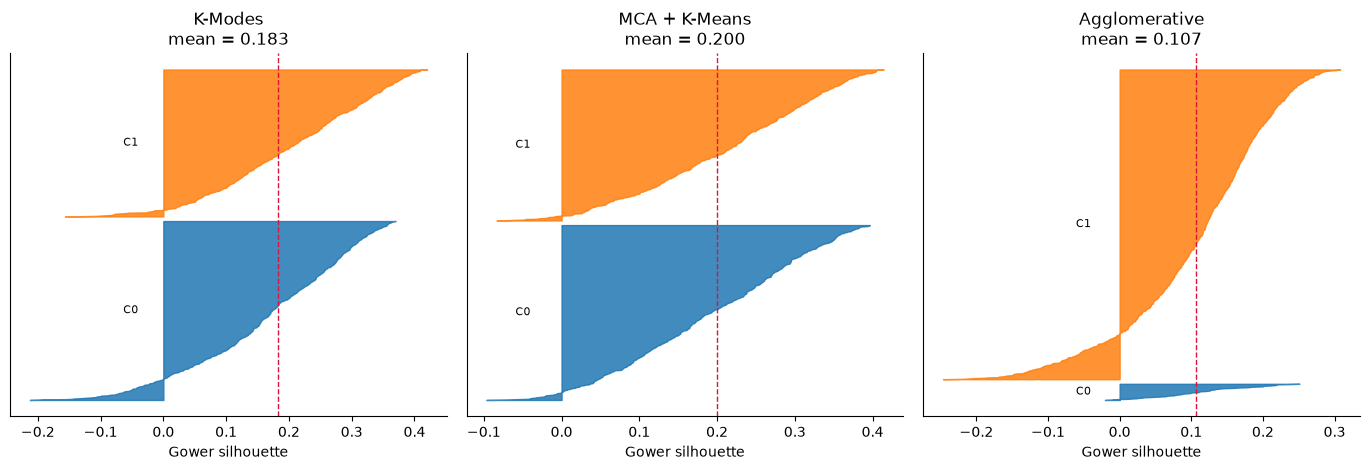

In [8]:
def gower_sil(labels):
    idx = np.flatnonzero(labels != -1)
    y = labels[idx]
    if idx.size < 3 or np.unique(y).size < 2:
        return np.nan, None, idx
    sub = D_gower[np.ix_(idx, idx)]
    return (
        float(silhouette_score(sub, y, metric="precomputed")),
        silhouette_samples(sub, y, metric="precomputed"),
        idx
    )


def sil_band(value):
    if not np.isfinite(value):
        return "undefined"
    return (
        "no substantial structure"
        if value < 0.25
        else (
            "weak-to-reasonable"
            if value <= 0.50
            else "reasonable-to-strong"
        )
    )


sil_results, sil_samples = {}, {}
for key in FAMILIES:
    value, samples, idx = gower_sil(partitions[key])
    sil_results[key] = value
    sil_samples[key] = (samples, idx)

common_footing = pd.DataFrame({
    "gower_silhouette": pd.Series(sil_results),
    "reading": pd.Series({k: sil_band(v) for k, v in sil_results.items()}),
    "profile_separation_mean_V": profile_separation.reindex(FAMILIES),
    "coverage": overview["coverage"],
    "balance": overview["balance"],
})
display(common_footing.round(3))

n_fam = len(FAMILIES)
fig, axes = plt.subplots(
    1,
    n_fam,
    figsize=(4.6 * n_fam, 4.8),
    squeeze=False
)
for ax, key in zip(axes[0], FAMILIES):
    samples, idx = sil_samples[key]
    labels = partitions[key][idx]
    y_lower = 0
    for c in sorted(np.unique(labels)):
        vals = np.sort(samples[labels == c])
        ax.fill_betweenx(
            np.arange(y_lower, y_lower + len(vals)),
            0,
            vals,
            color=CLUSTER_CMAP(int(c) % 10),
            alpha=0.85
        )
        ax.text(
            -0.04,
            y_lower + len(vals) / 2,
            cname(key, c),
            fontsize=8,
            va="center",
            ha="right"
        )
        y_lower += len(vals) + 15
    ax.axvline(
        sil_results[key],
        color="crimson",
        linestyle="--",
        linewidth=1
    )
    ax.set(
        title=f"{key}\nmean = {sil_results[key]:.3f}",
        xlabel="Gower silhouette", yticks=[]
    )
    ax.grid(False)
save_figure(fig, "silhouette_profiles.png")

### 5.3 Resampling stability on identical footing
A segmentation is only useful if it survives reasonable changes to the sample. For each of `N_RESAMPLES` random 80% subsamples (the **same** subsamples for every family, so differences are paired):

1. The family's representative configuration is **refitted from scratch on the subsample**: K-Modes (Huang, best-of-n starts), MCA + K-Means (MCA recomputed on the subsample, held-out respondents projected with the transition formula, then K-Means), average-linkage (or the configured linkage) on the Gower submatrix, and HDBSCAN with the chosen parameters.
2. Respondents outside the subsample are assigned by the family's own rule: nearest K-Modes mode, nearest K-Means centroid, or smallest mean Gower distance to a cluster's subsample members for the two Gower-based methods.
3. Two quantities are recorded against the Notebook 03 reference partition: **ARI** (computed on respondents the reference clusters; resample noise counts as its own label) and each reference cluster's **best-match Jaccard** similarity.

ARI measures the stability of the partition as a whole. The Jaccard of the *worst* cluster reveals whether any single cluster is an artefact. Jaccard below 0.60 indicates an unstable cluster, 0.60–0.75 a pattern of limited reliability, above 0.75 a stable cluster (Hennig, 2007).

In [9]:
Z = X_mca_indicator.to_numpy(dtype=np.float64)
N_MCA_COMPONENTS = int(modelling_meta["mca"]["n_components"])
KMODES_N_INIT = int(modelling_meta["kmodes"]["n_init_per_repeat"])
X_codes = np.column_stack(
    [
        pd.Categorical(X_kmodes[c]).codes.astype(np.int32)
        for c in PRIMARY_FEATURES
    ]
)


def mca_fit(Z_sub: np.ndarray, n_comp: int) -> np.ndarray:
    """Column standard coordinates G (q x n_comp) from an MCA fitted on Z_sub."""
    n_s = Z_sub.shape[0]
    P = Z_sub / (n_s * Q)
    r, c = P.sum(axis=1), P.sum(axis=0)
    keep = c > 0
    S = (P[:, keep] - np.outer(r, c[keep])) / np.sqrt(np.outer(r, c[keep]))
    _, _, Vt = np.linalg.svd(S, full_matrices=False)
    G = np.zeros((Z_sub.shape[1], n_comp))
    G[keep] = Vt[:n_comp].T / np.sqrt(c[keep])[:, None]
    return G


def mca_project(Z_any: np.ndarray, G: np.ndarray) -> np.ndarray:
    """Row principal coordinates of (supplementary) rows: row profile @ column standard coordinates."""
    return (Z_any / Q) @ G


# Reference MCA on the full cohort; verify the projection identity against the SVD definition.
G_full = mca_fit(Z, N_MCA_COMPONENTS)
mca_coords = mca_project(Z, G_full)
_P = Z / (N * Q)
_r, _c = _P.sum(axis=1), _P.sum(axis=0)
_U, _s, _ = np.linalg.svd(
    (_P - np.outer(_r, _c)) / np.sqrt(np.outer(_r, _c)),
    full_matrices=False
)
_direct = _U[:, :N_MCA_COMPONENTS] * _s[:N_MCA_COMPONENTS] / np.sqrt(_r)[:, None]
assert np.allclose(np.abs(mca_coords), np.abs(_direct), atol=1e-8), "MCA projection identity failed."
mca_eigenvalues = _s ** 2


def assign_by_distance(sub_idx, sub_labels, reduce="mean"):
    out = np.full(N, -1, dtype=int)
    out[sub_idx] = sub_labels
    clusters = np.unique(sub_labels[sub_labels != -1])
    held = np.setdiff1d(np.arange(N), sub_idx)
    if clusters.size == 0 or held.size == 0:
        return out
    cols = []
    for c in clusters:
        block = D_gower[np.ix_(held, sub_idx[sub_labels == c])]
        cols.append(
            block.mean(axis=1)
            if reduce == "mean"
            else block.max(axis=1)
        )
    out[held] = clusters[
        np.argmin(
            np.column_stack(cols),
            axis=1
        )
    ]
    return out


def refit_kmodes(sub_idx, seed):
    k = int(REPRESENTATIVES["K-Modes"]["k"])
    m = KModes(
        n_clusters=k,
        init="Huang",
        n_init=KMODES_N_INIT,
        max_iter=100,
        random_state=seed,
        n_jobs=1
    )
    m.fit(X_codes[sub_idx])
    mism = (
        X_codes[:, None, :] != np.asarray(m.cluster_centroids_)[None, :, :]
    ).sum(axis=2)
    return mism.argmin(axis=1)


def refit_kmeans(sub_idx, seed):
    k = int(REPRESENTATIVES["MCA + K-Means"]["k"])
    G = mca_fit(Z[sub_idx], N_MCA_COMPONENTS)
    coords = mca_project(Z, G)
    m = KMeans(
        n_clusters=k,
        n_init=10,
        max_iter=500,
        random_state=seed,
        algorithm="lloyd"
    ).fit(coords[sub_idx])
    return m.predict(coords)


def refit_agglomerative(sub_idx, seed):
    cfg = REPRESENTATIVES["Agglomerative"]
    method, k = cfg["linkage"], int(cfg["k_requested"])
    sub_D = D_gower[np.ix_(sub_idx, sub_idx)]
    tree = linkage(
        squareform(sub_D, checks=False),
        method=method
    )
    sub_labels = fcluster(tree, t=k, criterion="maxclust") - 1
    return assign_by_distance(
        sub_idx,
        sub_labels,
        reduce="max" if method == "complete" else "mean"
    )


def refit_hdbscan(sub_idx, seed):
    cfg = REPRESENTATIVES["HDBSCAN"]
    m = HDBSCAN(
        min_cluster_size=int(cfg["min_cluster_size"]),
        min_samples=int(cfg["min_samples"]),
        metric="precomputed",
        algorithm="generic",
        cluster_selection_method=cfg["cluster_selection_method"],
        allow_single_cluster=False,
        core_dist_n_jobs=1
    )
    sub_labels = m.fit_predict(np.ascontiguousarray(D_gower[np.ix_(sub_idx, sub_idx)]))
    return assign_by_distance(sub_idx, sub_labels)


REFITTERS = {
    "K-Modes": refit_kmodes,
    "MCA + K-Means": refit_kmeans,
    "Agglomerative": refit_agglomerative,
    "HDBSCAN": refit_hdbscan
}


def best_jaccard_per_cluster(reference, resampled):
    out = {}
    res_clusters = np.unique(resampled[resampled != -1])
    for c in np.unique(reference[reference != -1]):
        in_c = reference == c
        best = 0.0
        for j in res_clusters:
            in_j = resampled == j
            inter = np.sum(in_c & in_j)
            best = max(best, inter / (in_c.sum() + in_j.sum() - inter))
        out[int(c)] = best
    return out


rng = np.random.default_rng(RANDOM_STATE + 777)
sub_size = int(round(SUBSAMPLE_FRACTION * N))
resample_rows, cluster_jaccard_rows = [], []
for b in range(N_RESAMPLES):
    sub_idx = np.sort(rng.choice(N, size=sub_size, replace=False))
    seed = int(rng.integers(0, 2**31 - 1))
    for key in FAMILIES:
        ref = partitions[key]
        res = np.asarray(REFITTERS[key](sub_idx, seed), dtype=int)
        mask = ref != -1
        jac = best_jaccard_per_cluster(ref, res)
        resample_rows.append({
            "model_key": key, "resample": b,
            "ari": adjusted_rand_score(ref[mask], res[mask]),
            "jaccard_mean": float(np.mean(list(jac.values()))),
            "jaccard_min": float(np.min(list(jac.values()))),
        })
        cluster_jaccard_rows += [
            {
                "model_key": key,
                "resample": b,
                "cluster": c,
                "jaccard": v
            }
            for c, v in jac.items()
        ]

resamples = pd.DataFrame(resample_rows)
cluster_jaccard = pd.DataFrame(cluster_jaccard_rows)
resamples.to_csv(
    RESULTS_DIR / "osmi_2016_resampling_stability.csv",
    index=False
)

per_cluster_stability = (
    cluster_jaccard
    .groupby(["model_key", "cluster"])["jaccard"]
    .mean()
    .rename("mean_jaccard")
    .reset_index()
)
stability_summary = (
    resamples
    .groupby("model_key")
    .agg(
        resampling_ari_mean=("ari", "mean"),
        resampling_ari_sd=("ari", "std"),
        jaccard_mean=("jaccard_mean", "mean"),
    ).reindex(FAMILIES)
)
stability_summary["jaccard_worst_cluster"] = (
    per_cluster_stability
    .groupby("model_key")["mean_jaccard"]
    .min()
    .reindex(FAMILIES)
)
display(stability_summary.round(3))
display(
    per_cluster_stability
    .pivot(
        index="cluster",
        columns="model_key",
        values="mean_jaccard"
    )[FAMILIES]
    .round(3)
)

,resampling_ari_mean,resampling_ari_sd,jaccard_mean,jaccard_worst_cluster
model_key,,,,
K-Modes,0.718,0.114,0.857,0.846
MCA + K-Means,0.939,0.047,0.969,0.967
Agglomerative,0.095,0.108,0.461,0.100


model_key,K-Modes,MCA + K-Means,Agglomerative
cluster,,,
0,0.867,0.972,0.100
1,0.846,0.967,0.822


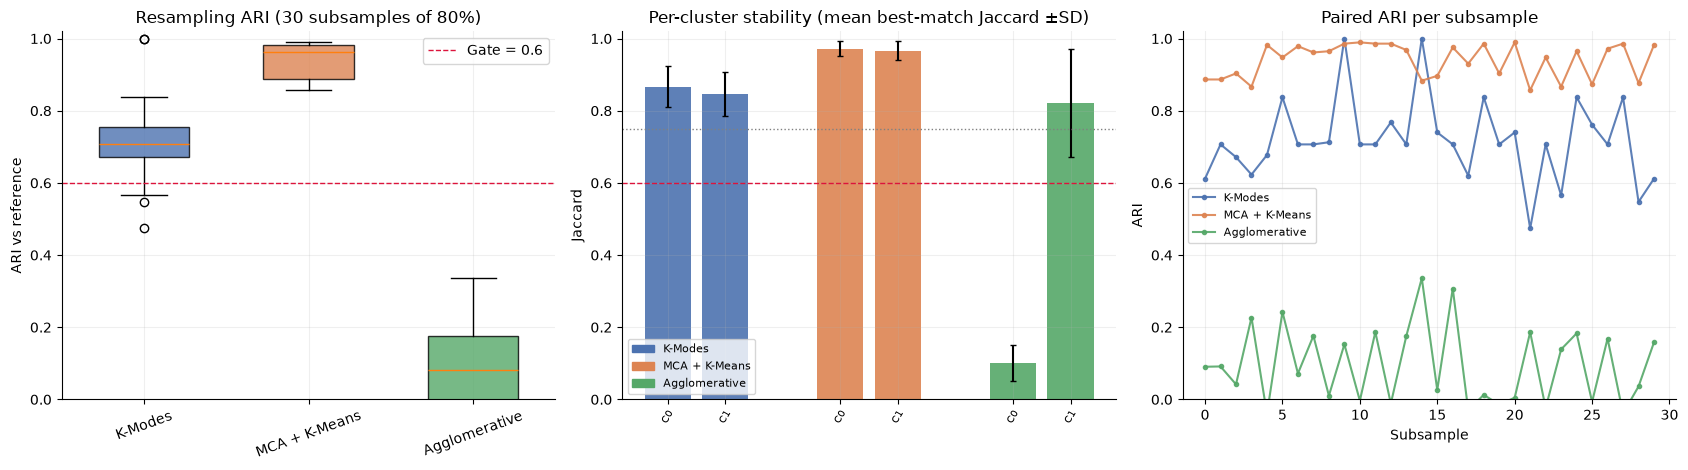

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
data = [resamples.loc[resamples["model_key"] == k, "ari"] for k in FAMILIES]
bp = axes[0].boxplot(
    data,
    tick_labels=FAMILIES,
    patch_artist=True,
    widths=0.55
)

for patch, k in zip(bp["boxes"], FAMILIES):
    patch.set_facecolor(FAMILY_COLOURS[k]); patch.set_alpha(0.8)

axes[0].axhline(
    GATE_ARI_FLOOR,
    color="crimson",
    linestyle="--",
    linewidth=1,
    label=f"Gate = {GATE_ARI_FLOOR}"
)
axes[0].set(
    title=f"Resampling ARI ({N_RESAMPLES} subsamples of {SUBSAMPLE_FRACTION:.0%})",
    ylabel="ARI vs reference",
    ylim=(0, 1.02)
)
axes[0].legend(); axes[0].tick_params(axis="x", rotation=20)

xpos, ticks, labels_ = 0, [], []
for key in FAMILIES:
    sub = cluster_jaccard[cluster_jaccard["model_key"] == key]
    for c in sorted(sub["cluster"].unique()):
        vals = sub.loc[sub["cluster"] == c, "jaccard"]
        axes[1].bar(
            xpos,
            vals.mean(),
            yerr=vals.std(ddof=1),
            color=FAMILY_COLOURS[key],
            capsize=2,
            alpha=0.9
        )
        ticks.append(xpos); labels_.append(cname(key, c)); xpos += 1
    xpos += 1

axes[1].axhline(
    GATE_JACCARD_FLOOR,
    color="crimson",
    linestyle="--",
    linewidth=1
)
axes[1].axhline(
    0.75,
    color="grey",
    linestyle=":",
    linewidth=1
)
axes[1].set_xticks(
    ticks,
    labels_,
    fontsize=7,
    rotation=60
)
axes[1].set(
    title="Per-cluster stability (mean best-match Jaccard ±SD)",
    ylabel="Jaccard",
    ylim=(0, 1.02)
)
axes[1].legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=FAMILY_COLOURS[k])
        for k in FAMILIES
    ],
    labels=FAMILIES,
    fontsize=8,
    loc="lower left"
)

pivot = resamples.pivot(
    index="resample",
    columns="model_key",
    values="ari"
)[FAMILIES]

for k in FAMILIES:
    axes[2].plot(
        pivot.index,
        pivot[k],
        marker="o",
        markersize=3,
        color=FAMILY_COLOURS[k],
        label=k,
        alpha=0.9
    )

axes[2].set(
    title="Paired ARI per subsample",
    xlabel="Subsample",
    ylabel="ARI",
    ylim=(0, 1.02)
)
axes[2].legend(fontsize=8)
save_figure(fig, "resampling_stability.png")

### 5.4 Agreement between families
If different methods, representations and distance definitions recover similar groupings, the structure is more likely to be a property of the data than of an algorithm. Agreement is measured by ARI and normalised mutual information on respondents clustered by both partitions. High agreement between two *K-type* methods is expected because both partition the same categorical profiles; agreement with the hierarchical or density-based method is stronger corroboration.

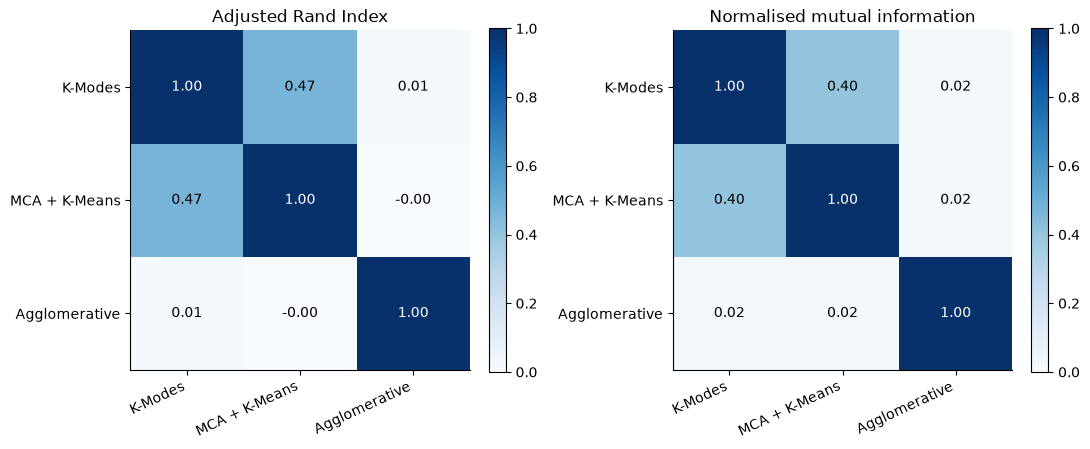

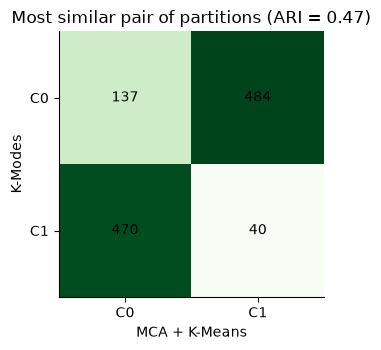

In [11]:
def pair_agreement(a, b):
    mask = (partitions[a] != -1) & (partitions[b] != -1)
    return (
        adjusted_rand_score(partitions[a][mask],
        partitions[b][mask]),
        normalized_mutual_info_score(
            partitions[a][mask],
            partitions[b][mask]),
            int(mask.sum()
        )
    )


ari_matrix = pd.DataFrame(
    np.eye(len(FAMILIES)),
    index=FAMILIES,
    columns=FAMILIES
)
nmi_matrix = ari_matrix.copy()

for a, b in combinations(FAMILIES, 2):
    ari, nmi, _ = pair_agreement(a, b)
    ari_matrix.loc[a, b] = ari_matrix.loc[b, a] = ari
    nmi_matrix.loc[a, b] = nmi_matrix.loc[b, a] = nmi

agreement = pd.concat(
    {
        "ARI": ari_matrix,
        "NMI": nmi_matrix
    }
)
agreement.to_csv(RESULTS_DIR / "osmi_2016_cross_family_agreement.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, mat, title in zip(
    axes,
    [ari_matrix, nmi_matrix],
    [
        "Adjusted Rand Index",
        "Normalised mutual information"
    ]
):
    im = ax.imshow(
        mat.to_numpy(),
        cmap="Blues",
        vmin=0,
        vmax=1
    )
    ax.set_xticks(
        range(len(FAMILIES)),
        FAMILIES,
        rotation=25,
        ha="right"
    )
    ax.set_yticks(range(len(FAMILIES)), FAMILIES)
    
    for i in range(len(FAMILIES)):
        for j in range(len(FAMILIES)):
            ax.text(
                j,
                i,
                f"{mat.iat[i, j]:.2f}",
                ha="center",
                va="center",
                color="white" if mat.iat[i, j] > 0.6 else "black"
            )

    ax.set_title(title); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)

save_figure(fig, "cross_family_agreement.png")

# Best-agreeing pair: contingency view
if len(FAMILIES) >= 2:
    pairs = [
        (a, b, pair_agreement(a, b)[0])
        for a, b in combinations(FAMILIES, 2)
    ]
    a, b, best_ari = max(pairs, key=lambda t: t[2])
    mask = (partitions[a] != -1) & (partitions[b] != -1)
    ct = pd.crosstab(
        pd.Series(partitions[a][mask]).map(lambda c: cname(a, c)).rename(a),
        pd.Series(partitions[b][mask]).map(lambda c: cname(b, c)).rename(b)
    )
    fig, ax = plt.subplots(
        figsize=(1.2 * ct.shape[1] + 3, 0.8 * ct.shape[0] + 2)
    )
    im = ax.imshow(ct.to_numpy(), cmap="Greens")
    ax.set_xticks(
        range(ct.shape[1]), ct.columns); ax.set_yticks(range(ct.shape[0]), ct.index
    )

    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(
                j,
                i,
                ct.iat[i, j],
                ha="center",
                va="center",
                fontsize=10
            )

    ax.set(
        xlabel=b,
        ylabel=a,
        title=f"Most similar pair of partitions (ARI = {best_ari:.2f})"
    )
    
    ax.grid(False)
    save_figure(fig, "closest_partition_contingency.png")

### 5.5 The candidates in the response space
Respondents are shown in the first two **MCA dimensions** and in a two-dimensional **classical (Torgerson) MDS** of the Gower dissimilarity, coloured by each family's clusters. Many respondents share identical response patterns, so points are jittered slightly. Two-dimensional projections retain only part of the structure (the MCA plane shows the share of inertia it carries); overlap in a projection does not by itself mean the clusters are inseparable, and clean separation would be visible here only if it is strong.

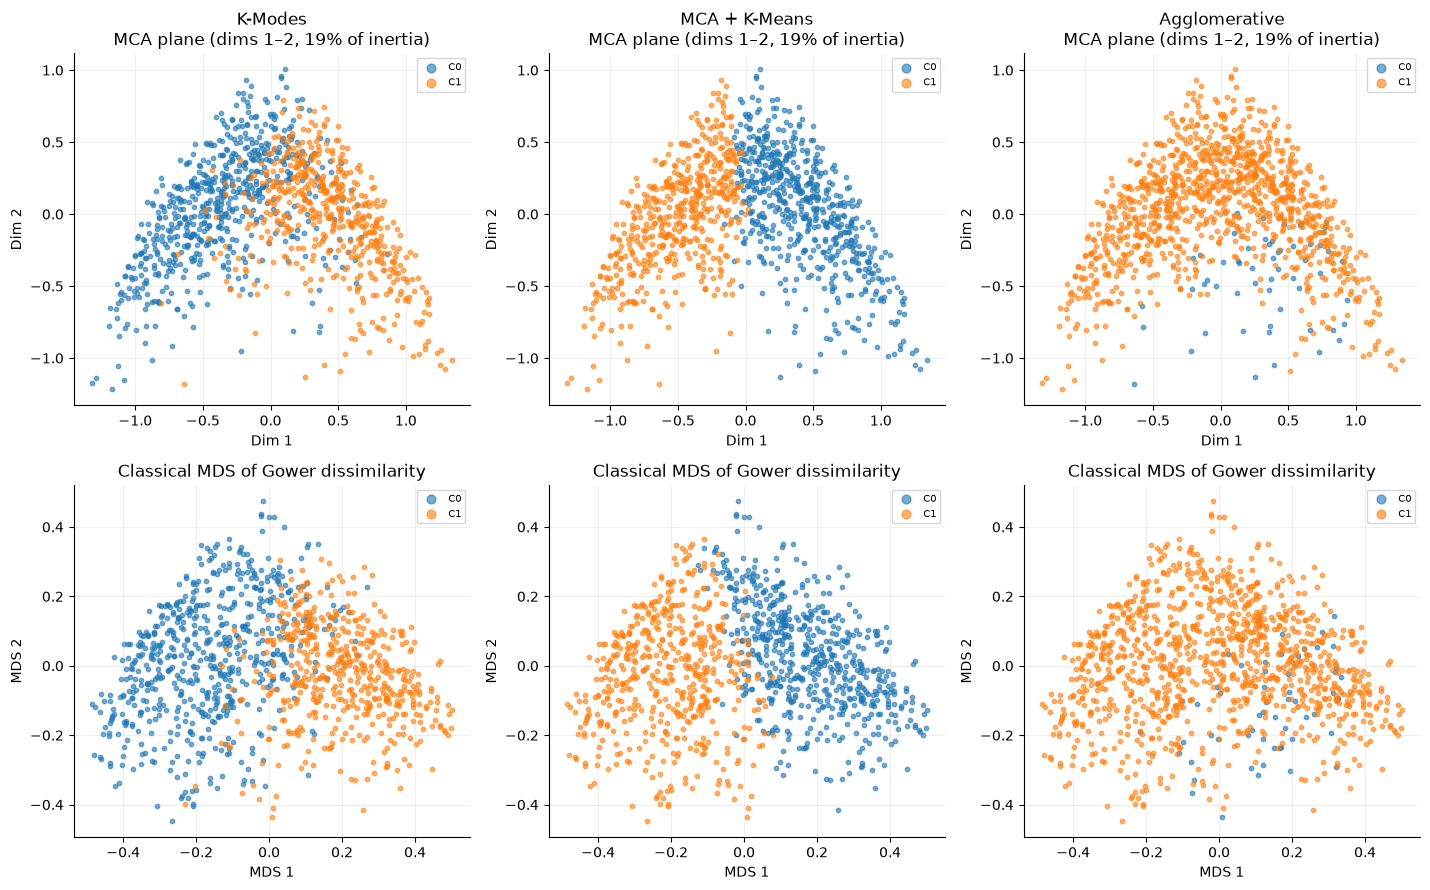

In [12]:
def classical_mds(D: np.ndarray, dims: int = 2):
    n = D.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    vals, vecs = np.linalg.eigh(B)
    order_ = np.argsort(vals)[::-1][:dims]
    vals, vecs = vals[order_], vecs[:, order_]
    return vecs * np.sqrt(np.maximum(vals, 0)), vals


mds_coords, mds_vals = classical_mds(D_gower)
jit = np.random.default_rng(RANDOM_STATE).normal(scale=0.01, size=(N, 2))
mca_plane = mca_coords[:, :2] + jit * np.ptp(mca_coords[:, :2], axis=0)
mds_plane = mds_coords + jit * np.ptp(mds_coords, axis=0)
mca_share = mca_eigenvalues[:2].sum() / mca_eigenvalues[: Z.shape[1] - Q].sum()


def scatter_partition(ax, plane, key):
    labels = partitions[key]
    if (
        labels == -1).any():
        ax.scatter(*plane[labels == -1].T,
        s=8,
        color="#cccccc",
        alpha=0.5,
        label="noise"
    )
        
    for c in sorted(np.unique(labels[labels != -1])):
        ax.scatter(
            *plane[labels == c].T,
            s=10,
            alpha=0.6,
            color=CLUSTER_CMAP(int(c) % 10),
            label=cname(key, c)
        )

    ax.legend(markerscale=2, fontsize=7, loc="best")


fig, axes = plt.subplots(
    2,
    len(FAMILIES),
    figsize=(4.8 * len(FAMILIES), 9),
    squeeze=False
)

for j, key in enumerate(FAMILIES):
    scatter_partition(axes[0, j], mca_plane, key)
    axes[0, j].set(
        title=f"{key}\nMCA plane (dims 1–2, {mca_share:.0%} of inertia)",
        xlabel="Dim 1", ylabel="Dim 2"
    )
    scatter_partition(axes[1, j], mds_plane, key)
    axes[1, j].set(
        title="Classical MDS of Gower dissimilarity",
        xlabel="MDS 1",
        ylabel="MDS 2"
    )
    
save_figure(fig, "candidates_in_response_space.png")

## 6. Model recommendation

### 6.1 Scorecard and gates
All values below are computed identically for every family. The gates were fixed in the notebook header before any result was inspected.

,n_clusters,smallest_cluster,coverage,balance,gower_silhouette,profile_separation,resampling_ari_mean,resampling_ari_sd,jaccard_worst_cluster,gates_passed,eligible
model_key,,,,,,,,,,,
K-Modes,2.0,510.0,1.0,0.993,0.183,0.374,0.718,0.114,0.846,5,True
MCA + K-Means,2.0,524.0,1.0,0.996,0.200,0.427,0.939,0.047,0.967,5,True
Agglomerative,2.0,57.0,1.0,0.288,0.107,0.163,0.095,0.108,0.100,3,False
HDBSCAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,False


,G1 representative declared,G2 smallest cluster ≥ 5%,G3 coverage ≥ 80%,G4 resampling ARI ≥ 0.60,G5 worst-cluster Jaccard ≥ 0.60
model_key,,,,,
K-Modes,pass,pass,pass,pass,pass
MCA + K-Means,pass,pass,pass,pass,pass
Agglomerative,pass,pass,pass,FAIL,FAIL
HDBSCAN,FAIL,FAIL,FAIL,FAIL,FAIL


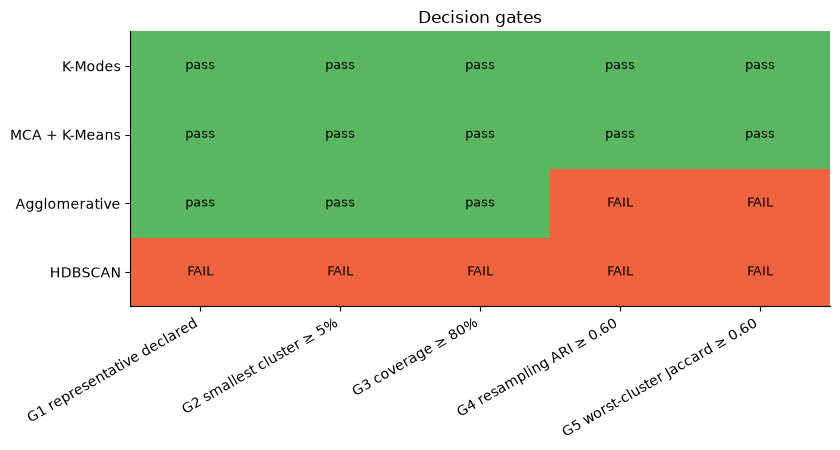

In [13]:
rows = []
for key in FAMILY_ORDER:
    declared = key in partitions
    row = {"model_key": key, "representative_declared": declared}
    if declared:
        ov = overview.loc[key]
        row.update({
            "n_clusters": int(ov["n_clusters"]),
            "smallest_cluster": int(ov["smallest_cluster"]),
            "coverage": float(ov["coverage"]),
            "balance": float(ov["balance"]),
            "gower_silhouette": float(sil_results[key]),
            "profile_separation": float(profile_separation[key]),
            "resampling_ari_mean": float(stability_summary.loc[key, "resampling_ari_mean"]),
            "resampling_ari_sd": float(stability_summary.loc[key, "resampling_ari_sd"]),
            "jaccard_worst_cluster": float(stability_summary.loc[key, "jaccard_worst_cluster"]),
        })
    rows.append(row)
scorecard = pd.DataFrame(rows).set_index("model_key")

gates = pd.DataFrame(index=scorecard.index)
gates["G1 representative declared"] = scorecard["representative_declared"]
gates["G2 smallest cluster ≥ 5%"] = scorecard["smallest_cluster"].ge(MIN_CLUSTER_SIZE)
gates["G3 coverage ≥ 80%"] = scorecard["coverage"].ge(GATE_MIN_COVERAGE)
gates["G4 resampling ARI ≥ 0.60"] = scorecard["resampling_ari_mean"].ge(GATE_ARI_FLOOR)
gates["G5 worst-cluster Jaccard ≥ 0.60"] = scorecard["jaccard_worst_cluster"].ge(GATE_JACCARD_FLOOR)
gates = gates.fillna(False).astype(bool)
scorecard["gates_passed"] = gates.sum(axis=1)
scorecard["eligible"] = gates.all(axis=1)

display(scorecard.drop(columns=["representative_declared"]).round(3))
display(gates.replace({True: "pass", False: "FAIL"}))

fig, ax = plt.subplots(figsize=(8.5, 0.7 * len(gates) + 1.8))
ax.imshow(
    gates.to_numpy(dtype=float),
    cmap="RdYlGn",
    vmin=-0.3,
    vmax=1.3,
    aspect="auto"
)
ax.set_xticks(
    range(gates.shape[1]),
    gates.columns,
    rotation=30,
    ha="right"
)
ax.set_yticks(range(gates.shape[0]), gates.index)

for i in range(gates.shape[0]):
    for j in range(gates.shape[1]):
        ax.text(
            j,
            i,
            "pass" if gates.iat[i, j] else "FAIL",
            ha="center",
            va="center",
            fontsize=9
        )
        
ax.set_title("Decision gates"); ax.grid(False)
save_figure(fig, "decision_gates.png")

### 6.2 Ranking, margins and weight sensitivity
Among the eligible families (or, if none is eligible, among all families with a representative, ordered first by gates passed), each criterion is converted to a rank percentile (1 = best, 0 = worst; a single contender scores 1). **Values within the declared `MATERIAL_MARGIN` of the leader are treated as tied**, so a gap of 0.017 in silhouette does not masquerade as a decisive win. The score is the equally weighted mean percentile; parsimony (fewer clusters) and then stability break ties.

Because rank percentiles discard magnitude, the **raw margin over the runner-up** is reported for every criterion, together with whether it is material. Finally, the weights are redrawn **`N_WEIGHT_DRAWS` times from a flat Dirichlet distribution** and the share of draws won by each family is reported. If the winner is never outranked on any criterion, it wins under *every* weighting, so the sensitivity result is uninformative rather than reassuring; the margins then carry the evidence.

,gates_passed,score,weight_sensitivity_win_share,resampling_ari_mean_pctl,jaccard_worst_cluster_pctl,gower_silhouette_pctl,profile_separation_pctl,coverage_pctl
model_key,,,,,,,,
MCA + K-Means,5,0.8,1.0,1.0,1.0,0.5,1.0,0.5
K-Modes,5,0.2,0.0,0.0,0.0,0.5,0.0,0.5


Raw margins: MCA + K-Means vs runner-up K-Modes


,winner,runner_up,difference,material_margin,reading
Resampling stability (ARI),0.939,0.718,0.221,0.05,material advantage
Worst-cluster stability (Jaccard),0.967,0.846,0.121,0.05,material advantage
Gower silhouette,0.200,0.183,0.017,0.03,practical tie
Response-profile separation (mean V),0.427,0.374,0.053,0.05,material advantage
Coverage,1.000,1.000,0.000,0.02,practical tie


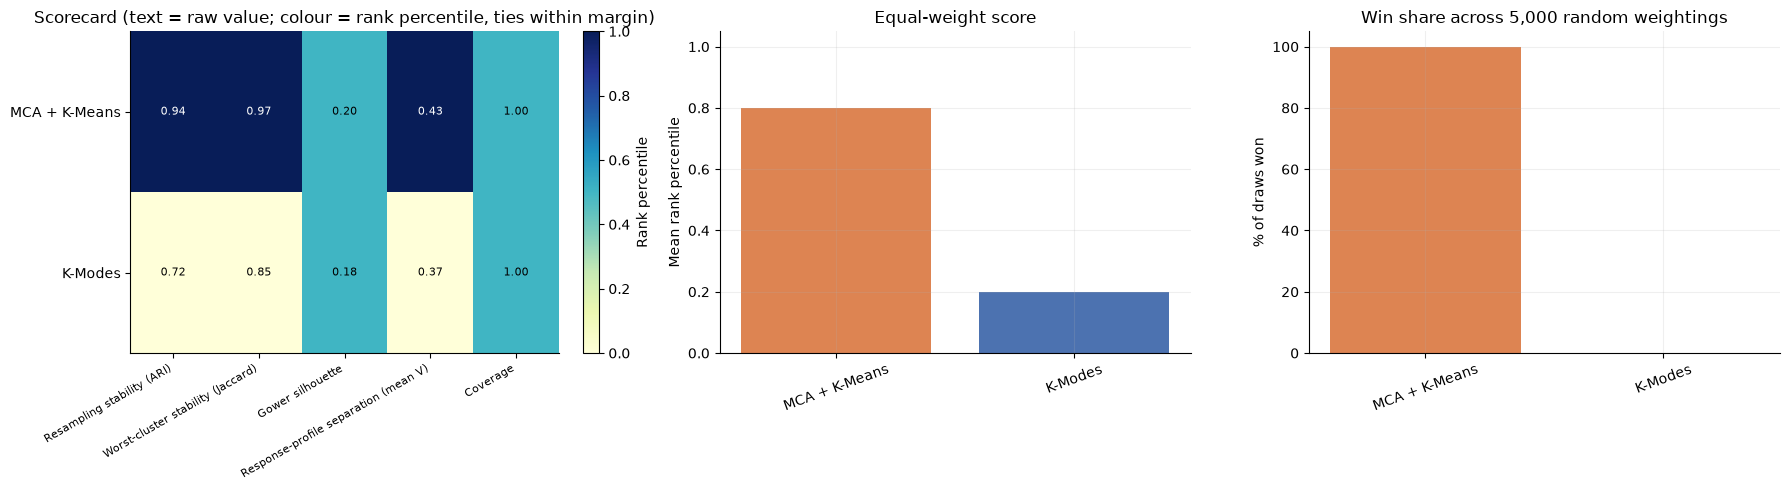

Status: recommended
Top-ranked family: MCA + K-Means
Weight-sensitivity win share: 100% (uninformative: the winner is never outranked, so it wins under every weighting)


In [14]:
declared = scorecard[scorecard["representative_declared"]].copy()
if declared.empty:
    raise RuntimeError("No family has a representative; nothing to evaluate.")

if declared["eligible"].any():
    pool = declared[declared["eligible"]].copy()
    STATUS = "recommended"
else:
    pool = declared.copy()
    STATUS = "provisional: no family passes every gate"

crit = list(CRITERIA)
m = len(pool)


def tolerant_percentile(values: pd.Series, tol: float) -> pd.Series:
    # Rank percentile (1 = best); values within `tol` of a group's leader share the average rank.
    n_ = len(values)
    if n_ == 1:
        return pd.Series(1.0, index=values.index)
    
    ordered = values.sort_values(ascending=False)
    vals, idxs = ordered.to_numpy(), ordered.index
    ranks = pd.Series(index=idxs, dtype=float)
    pos, i = 1, 0

    while i < n_:
        j = i
        while j + 1 < n_ and vals[i] - vals[j + 1] <= tol:
            j += 1
        ranks.iloc[i:j + 1] = pos + (j - i) / 2
        pos += j - i + 1
        i = j + 1
    return (n_ - ranks) / (n_ - 1)


percentile = pd.DataFrame(
    {
        c: tolerant_percentile(pool[c], MATERIAL_MARGIN[c])
        for c in crit
    },
    index=pool.index
)


def score_with(weights):
    return percentile.to_numpy() @ weights


equal_w = np.full(len(crit), 1 / len(crit))
pool["score"] = score_with(equal_w)
pool = pool.sort_values(
    [
        "gates_passed",
        "score",
        "n_clusters",
        "resampling_ari_mean"
    ],
    ascending=[False, False, True, False],
)
WINNER = pool.index[0]

# --- Raw margins of the winner over the runner-up ---
margin_table, MATERIAL_ADVANTAGE, PRACTICAL_TIES, DOMINANT, RUNNER_UP = None, [], [], False, None
if m > 1:
    RUNNER_UP = pool.index[1]
    diff = pool.loc[WINNER, crit].astype(float) - pool.loc[RUNNER_UP, crit].astype(float)
    tol = pd.Series(MATERIAL_MARGIN)[crit]
    margin_table = pd.DataFrame({
        "winner": pool.loc[WINNER, crit].astype(float), "runner_up": pool.loc[RUNNER_UP, crit].astype(float),
        "difference": diff, "material_margin": tol,
        "reading": np.where(
            diff > tol,
            "material advantage",
            np.where(
                diff < -tol,
                "material disadvantage",
                "practical tie"
            )
        ),
    })
    margin_table.index = [CRITERIA[c] for c in crit]
    MATERIAL_ADVANTAGE = [c for c in crit if diff[c] > tol[c]]
    PRACTICAL_TIES = [c for c in crit if abs(diff[c]) <= tol[c]]

    # Not outranked: no other eligible family has a material advantage on any criterion
    DOMINANT = all(
        (pool.loc[WINNER, c] - pool.loc[o, c]) >= -MATERIAL_MARGIN[c]
        for o in pool.index[1:]
        for c in crit
    )

# --- Weight sensitivity ---
rng_w = np.random.default_rng(RANDOM_STATE + 99)
draws = rng_w.dirichlet(np.ones(len(crit)), size=N_WEIGHT_DRAWS)
draw_scores = percentile.to_numpy() @ draws.T                       # families x draws
best_idx = np.argmax(
    draw_scores + 1e-9 * (-pool.loc[percentile.index, "n_clusters"].to_numpy()[:, None]),
    axis=0
)
win_share = pd.Series(
    np.bincount(best_idx, minlength=m) / N_WEIGHT_DRAWS, index=percentile.index
).reindex(pool.index)
pool["weight_sensitivity_win_share"] = win_share
WIN_SHARE = float(win_share[WINNER])

if DOMINANT and m > 1:
    ROBUSTNESS = "uninformative: the winner is never outranked, so it wins under every weighting"
else:
    ROBUSTNESS = "robust" if WIN_SHARE >= 0.70 else ("moderate" if WIN_SHARE >= 0.50 else "fragile")

display(
    pd.concat(
        [
            pool[
                [
                    "gates_passed",
                    "score",
                    "weight_sensitivity_win_share"
                ]
            ],
            percentile.add_suffix("_pctl").loc[pool.index]
        ],
        axis=1
    ).round(3)
)

if margin_table is not None:
    print(f"Raw margins: {WINNER} vs runner-up {RUNNER_UP}")
    display(margin_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pct_plot = percentile.loc[pool.index]
im = axes[0].imshow(
    pct_plot.to_numpy(),
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    aspect="auto"
)

axes[0].set_xticks(
    range(len(crit)),
    [CRITERIA[c] for c in crit],
    rotation=30,
    ha="right",
    fontsize=8
)

axes[0].set_yticks(range(len(pct_plot)), pct_plot.index)

for i in range(pct_plot.shape[0]):
    for j, c in enumerate(crit):
        axes[0].text(
            j,
            i,
            f"{pool.loc[pct_plot.index[i], c]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if pct_plot.iat[i, j] > 0.6 else "black"
        )

axes[0].set(title="Scorecard (text = raw value; colour = rank percentile, ties within margin)")
axes[0].grid(False)

fig.colorbar(
    im,
    ax=axes[0],
    fraction=0.04,
    label="Rank percentile"
)

axes[1].bar(
    pool.index,
    pool["score"],
    color=[FAMILY_COLOURS[k] for k in pool.index]
)
axes[1].set(
    title="Equal-weight score",
    ylabel="Mean rank percentile",
    ylim=(0, 1.05)
)
axes[1].tick_params(axis="x", rotation=20)
axes[2].bar(
    win_share.index,
    win_share * 100,
    color=[FAMILY_COLOURS[k] for k in win_share.index]
)
axes[2].set(
    title=f"Win share across {N_WEIGHT_DRAWS:,} random weightings",
    ylabel="% of draws won",
    ylim=(0, 105)
)
axes[2].tick_params(axis="x", rotation=20)

for ax in axes[1:]:
    ax.grid(axis="y", alpha=0.2)

save_figure(fig, "scorecard_and_sensitivity.png")

scorecard_out = scorecard.join(pool[["score", "weight_sensitivity_win_share"]])
scorecard_out.to_csv(RESULTS_DIR / "osmi_2016_model_scorecard.csv")

if margin_table is not None:
    margin_table.to_csv(RESULTS_DIR / "osmi_2016_winner_margins.csv")

print(
    f"Status: {STATUS}\nTop-ranked family: {WINNER}\n"
    f"Weight-sensitivity win share: {WIN_SHARE:.0%} ({ROBUSTNESS})"
)

## 7. Deep dive: the recommended partition

Everything in this section refers to the top-ranked family from Section 6 and is regenerated automatically if the ranking changes. If the status above is *provisional*, read this section as exploratory.

### 7.1 How the configuration was chosen within its family
The chosen setting is shown against the alternatives Notebook 03 evaluated, so the reader can see whether the choice sits on a clear optimum or a flat plateau.

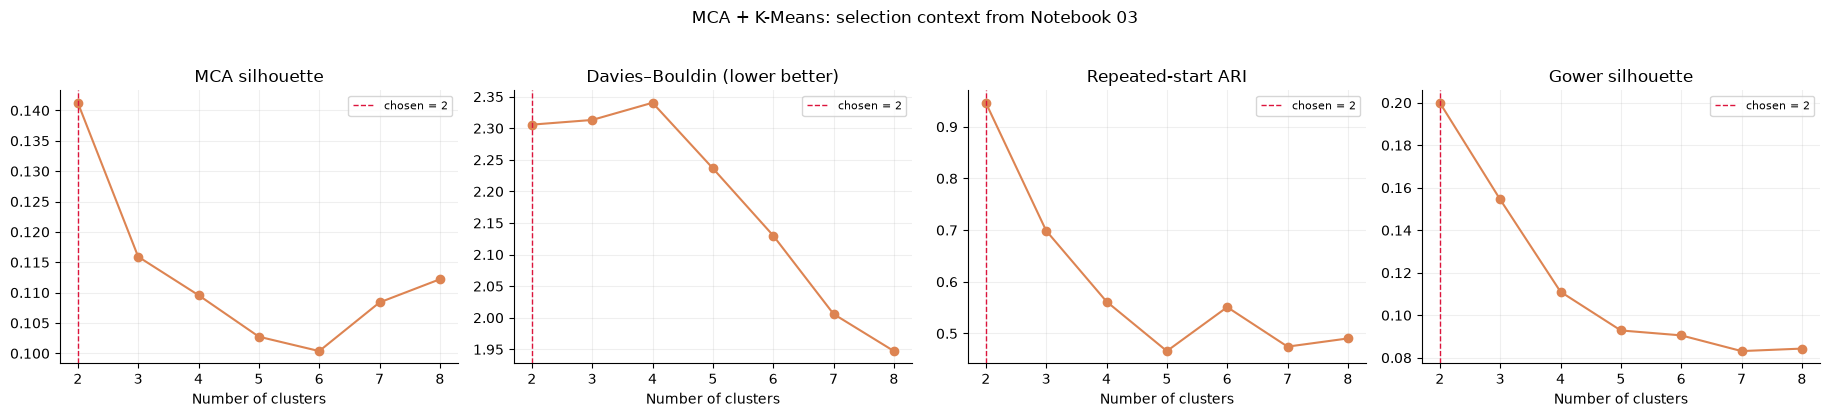

In [15]:
def plot_selection_context(key):
    g = grid_results[grid_results["model_key"] == key]
    cfg = REPRESENTATIVES[key]

    if key == "K-Modes":
        panels = [
            ("gower_silhouette", "Gower silhouette"),
            ("mean_pairwise_ari", "Repeated-run ARI"),
            ("resampling_ari_mean", "Resampling ARI"),
            ("cost_per_respondent", "Cost / respondent")
        ]
        x, chosen = "k_requested", cfg["k"]
    elif key == "MCA + K-Means":
        panels = [
            ("mca_silhouette", "MCA silhouette"),
            ("davies_bouldin", "Davies–Bouldin (lower better)"),
            ("mean_pairwise_ari", "Repeated-start ARI"),
            ("gower_silhouette", "Gower silhouette")
        ]
        x, chosen = "k_requested", cfg["k"]
    elif key == "Agglomerative":
        g = g[g["linkage"] == cfg["linkage"]]
        panels = [
            ("gower_silhouette", "Gower silhouette"),
            ("smallest_cluster_size", "Smallest cluster (respondents)")
        ]
        x, chosen = "k_actual", cfg["k_actual"]
    else:
        fig, ax = plt.subplots(figsize=(7, 5))
        ok = g[g["n_clusters"] >= 2]
        ax.scatter(
            ok["coverage"],
            ok["dbcv"],
            color="#bbbbbb",
            s=40,
            label="other configurations"
        )
        pick = ok[ok["config_key"] == cfg["config_key"]]
        ax.scatter(
            pick["coverage"],
            pick["dbcv"],
            color=FAMILY_COLOURS[key],
            s=120,
            edgecolor="black",
            label="chosen"
        )
        ax.set(
            xlabel="Coverage",
            ylabel="DBCV",
            title="HDBSCAN configurations"
        )
        ax.legend()
        return fig
    
    fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4))

    for ax, (col, title) in zip(np.atleast_1d(axes), panels):
        ax.plot(g[x], g[col], marker="o", color=FAMILY_COLOURS[key])
        ax.axvline(
            chosen,
            color="crimson",
            linestyle="--",
            linewidth=1,
            label=f"chosen = {chosen}"
        )
        ax.set(title=title, xlabel="Number of clusters")
        if col == "smallest_cluster_size":
            ax.axhline(
                MIN_CLUSTER_SIZE,
                color="grey",
                linestyle=":",
                linewidth=1
            )
            ax.set_yscale("log")
        ax.legend(fontsize=8)
    return fig


fig = plot_selection_context(WINNER)
fig.suptitle(f"{WINNER}: selection context from Notebook 03", y=1.03)
save_figure(fig, "recommended_selection_context.png")

### 7.2 Response distributions by cluster (all 15 items)
Each panel shows, for one clustering item, the distribution of responses within each cluster. Items on which the bars differ clearly between clusters are those that define the segmentation; items with similar bars contribute little.

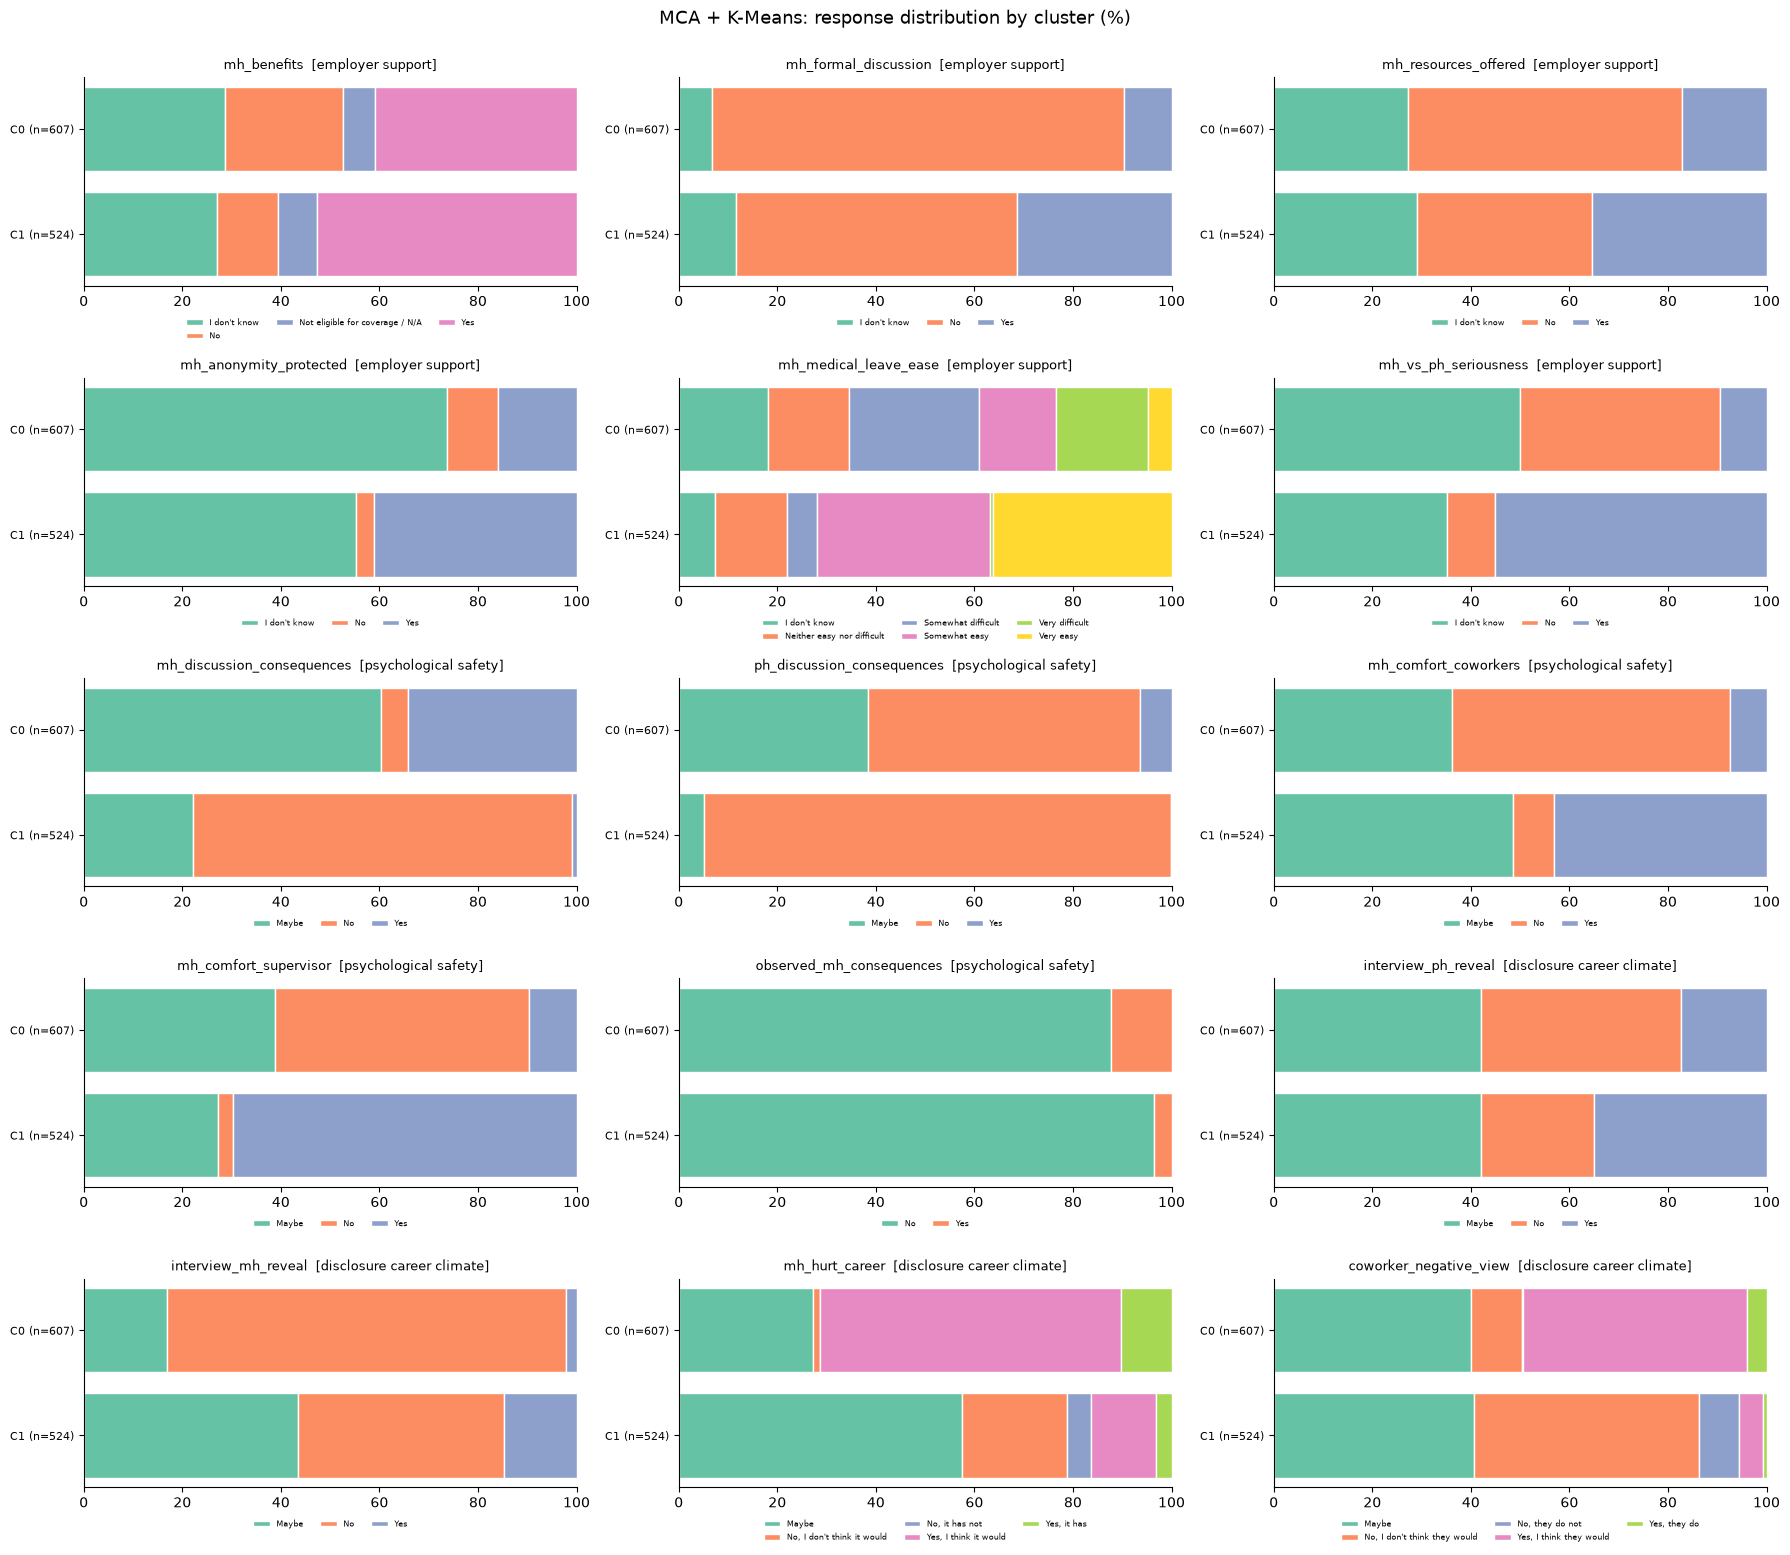

In [16]:
winner_labels = partitions[WINNER]
frame_w = clustered_frame(winner_labels)
clusters_w = sorted(frame_w["cluster"].unique())
cluster_sizes_w = frame_w["cluster"].value_counts()

n_cols = 3
n_rows = int(math.ceil(len(PRIMARY_FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.1 * n_rows))
axes = axes.ravel()

for ax, f in zip(axes, PRIMARY_FEATURES):
    ct = pd.crosstab(
        frame_w["cluster"],
        frame_w[f],
        normalize="index"
    )
    palette = plt.get_cmap("Set2")
    left = np.zeros(len(ct))

    for i, cat in enumerate(ct.columns):
        ax.barh(
            range(len(ct)),
            ct[cat].to_numpy() * 100,
            left=left * 100,
            color=palette(i % 8),
            edgecolor="white",
            label=str(cat)
        )
        left += ct[cat].to_numpy()

    ax.set_yticks(
        range(len(ct)),
        [f"{cname(WINNER, c)} (n={cluster_sizes_w[c]})" for c in ct.index],
        fontsize=8
    )
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_title(f"{f}  [{FEATURE_DOMAIN[f].replace('_', ' ')}]", fontsize=9)
    ax.legend(
        fontsize=6,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=3,
        frameon=False
    )
    ax.grid(False)

for ax in axes[len(PRIMARY_FEATURES):]:
    ax.axis("off")

fig.suptitle(
    f"{WINNER}: response distribution by cluster (%)",
    y=1.0,
    fontsize=13
)
save_figure(fig, "recommended_response_distributions.png")

### 7.3 Distinguishing responses and the uncertainty pattern
The first table lists each cluster's most distinctive responses (Section 4.3 rules). The second summarises, for each cluster and domain, how often respondents chose an *uncertain* response (for example "I don't know", "Not sure", "Maybe"; pattern in `UNCERTAIN_PATTERN`). This separates clusters that differ in *attitude* from clusters that differ mainly in *awareness*. The categories matched by the pattern are listed so the reader can verify them against the Notebook 02 coding.

,cluster,cluster_size,feature,category,share_in_cluster,share_overall,pp_diff_vs_rest,lift
0,C0,607,mh_comfort_supervisor,No,0.516,0.291,48.512,1.773
1,C0,607,mh_comfort_coworkers,No,0.563,0.341,47.946,1.651
2,C0,607,mh_hurt_career,"Yes, I think it would",0.611,0.390,47.761,1.568
3,C0,607,coworker_negative_view,"Yes, I think they would",0.455,0.266,40.699,1.709
4,C1,524,mh_discussion_consequences,No,0.769,0.385,71.472,1.995
5,C1,524,mh_comfort_supervisor,Yes,0.697,0.375,59.937,1.858
6,C1,524,mh_vs_ph_seriousness,Yes,0.552,0.306,45.762,1.803
7,C1,524,ph_discussion_consequences,No,0.947,0.735,39.467,1.288


Categories treated as 'uncertain':


,feature,category,n
0,coworker_negative_view,Maybe,456
1,interview_mh_reveal,Maybe,331
2,interview_ph_reveal,Maybe,475
3,mh_anonymity_protected,I don't know,736
4,mh_benefits,I don't know,316
5,mh_comfort_coworkers,Maybe,474
6,mh_comfort_supervisor,Maybe,378
7,mh_discussion_consequences,Maybe,482
8,mh_formal_discussion,I don't know,102
9,mh_hurt_career,Maybe,466


,employer_support (% uncertain),psychological_safety (% uncertain),disclosure_career_climate (% uncertain)
cluster,,,
C0,36.8,34.7,31.5
C1,30.0,20.6,45.9


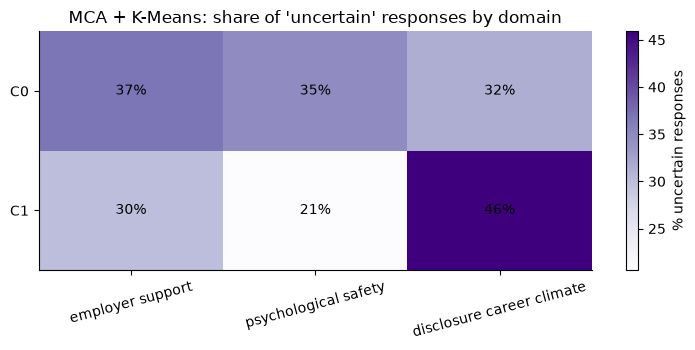

In [18]:
display(
    distinctive[WINNER]
    .assign(
        cluster=lambda d: d["cluster"]
        .map(lambda c: cname(WINNER, c))
    )
    .round(3)
)

uncertain = pd.DataFrame({
    f: (
        X_kmodes[f]
        .str
        .contains(UNCERTAIN_PATTERN,case=False, regex=True, na=False)
        .astype("boolean")
        .fillna(False)
        .to_numpy(dtype=bool)
    )
    for f in PRIMARY_FEATURES
}).astype(float)

matched = (
    X_kmodes
    .melt(var_name="feature", value_name="category")
    .loc[
        lambda d: d["category"].str.contains(
            UNCERTAIN_PATTERN,
            case=False,
            regex=True,
            na=False
        )
    ]
    .groupby(["feature", "category"])
    .size()
    .rename("n")
    .reset_index()
)

if matched.empty:
    print("No response categories matched UNCERTAIN_PATTERN; uncertainty profile skipped.")
else:
    print("Categories treated as 'uncertain':")
    display(matched)
    mask = winner_labels != -1
    dom_unc = pd.DataFrame(
        {
            d:
            uncertain
            .loc[mask, fs]
            .mean(axis=1)
            .groupby(winner_labels[mask])
            .mean()
            for d, fs in FEATURES_BY_DOMAIN.items()
        }
    )

    dom_unc.index = [cname(WINNER, c) for c in dom_unc.index]

    display(
        (dom_unc * 100)
        .round(1)
        .rename_axis("cluster")
        .add_suffix(" (% uncertain)")
    )

    fig, ax = plt.subplots(figsize=(7.5, 0.8 * len(dom_unc) + 2))
    
    im = ax.imshow(
        dom_unc.to_numpy() * 100,
        cmap="Purples",
        aspect="auto"
    )
    ax.set_xticks(
        range(dom_unc.shape[1]),
        [c.replace("_", " ") for c in dom_unc.columns],
        rotation=15
    )

    ax.set_yticks(range(dom_unc.shape[0]), dom_unc.index)

    for i in range(dom_unc.shape[0]):
        for j in range(dom_unc.shape[1]):
            ax.text(
                j,
                i,
                f"{dom_unc.iat[i, j] * 100:.0f}%",
                ha="center",
                va="center"
            )

    ax.set_title(f"{WINNER}: share of 'uncertain' responses by domain"); ax.grid(False)
    fig.colorbar(im, ax=ax, label="% uncertain responses")
    save_figure(fig, "recommended_uncertainty_by_domain.png")

### 7.4 Contextual (non-clustering) variables: descriptive only
If Notebook 02 persisted a cleaned dataset containing contextual variables, they are joined to the clusters **after** clustering through `source_row_position`. This answers "who tends to be in each cluster?" and nothing more. These variables were never clustering inputs; they are not proxies for health status; and **no diagnosis, treatment or suspected-condition variable is read** (only the columns in `CONTEXT_COLUMNS` are loaded). Because the clusters were formed from the same respondents, p-values are descriptive and optimistic. Effect sizes are the quantity to read: Cramér's V below 0.10 is negligible, 0.10–0.20 small, 0.20–0.30 moderate; ε² for age uses the analogous 0.01 / 0.06 / 0.14 bands.

Context source: osmi_2016_cleaned_respondents.csv; variables: ['age', 'gender', 'company_size', 'work_remote', 'tech_company', 'tech_role', 'country_work']; matched respondents: 1,131/1,131


,variable,type,effect_size,metric,p_value,summary,p_adj_BH,magnitude
0,age,numeric,0.0007,epsilon²,0.1799,C0 median 32; C1 median 32,0.2395,negligible
1,gender,categorical,0.1029,Cramér's V,0.0046,6 response groups,0.0139,small
2,company_size,categorical,0.0463,Cramér's V,0.1905,6 response groups,0.2395,negligible
3,work_remote,categorical,0.1604,Cramér's V,0.0000,3 response groups,0.0000,small
4,tech_company,categorical,0.0239,Cramér's V,0.1996,2 response groups,0.2395,negligible
5,country_work,categorical,0.0152,Cramér's V,0.3843,6 response groups,0.3843,negligible


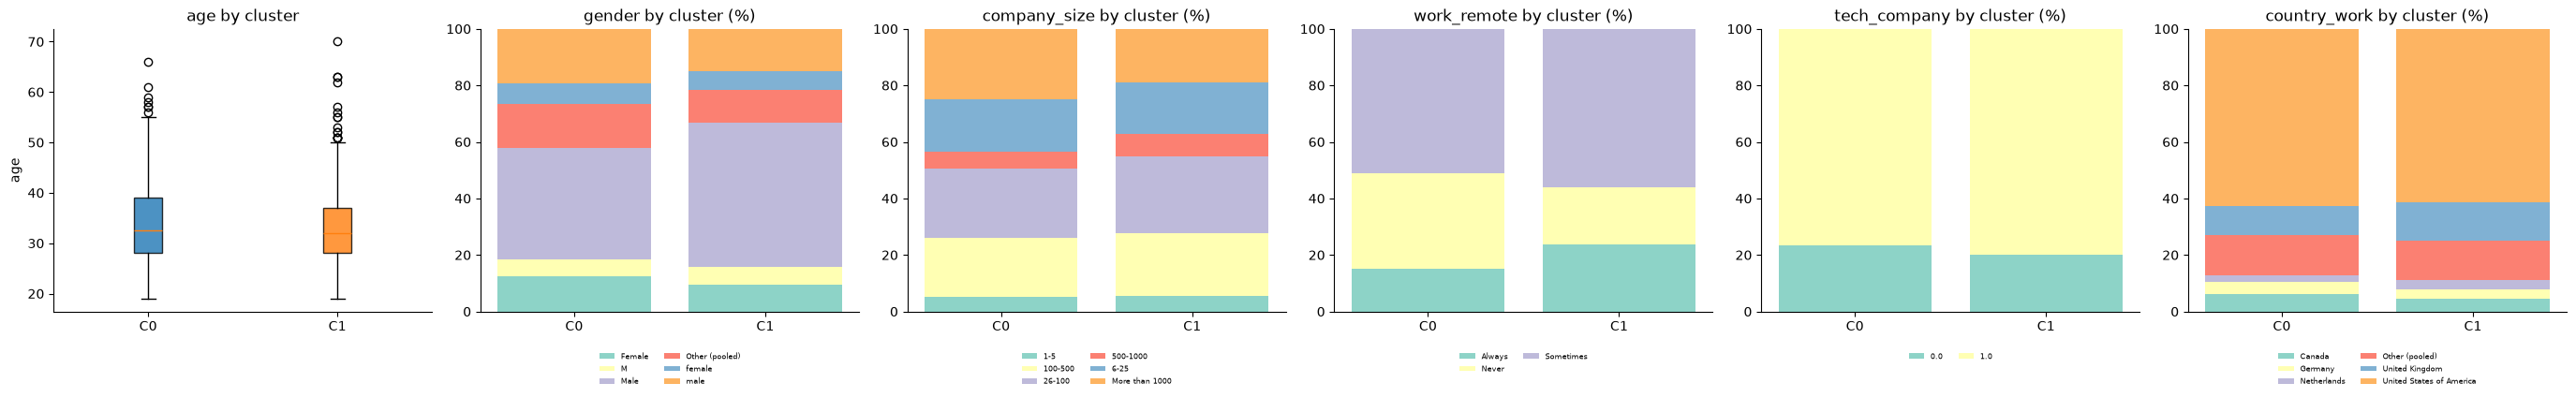

In [19]:
CONTEXT_COLUMNS = [
    "age",
    "gender",
    "company_size",
    "work_remote",
    "tech_company",
    "tech_role",
    "country_work"
]
AGE_RANGE = (18, 75)           # same plausibility window used for age review in Notebook 01
model_input_names = {p.name for p in NB2_FILES.values()}


def find_context_file():
    if "source_row_position" not in row_mapping.columns:
        return None
    best = None
    for path in sorted(PROCESSED_DIR.glob("*.csv")):
        if path.name in model_input_names:
            continue
        try:
            head = pd.read_csv(path, nrows=2)
        except Exception:
            continue
        cols = [c for c in CONTEXT_COLUMNS if c in head.columns]
        if (
            "source_row_position" in head.columns
            and cols
            and (best is None or len(cols) > len(best[1]))
        ):
            best = (path, cols)
    return best


def benjamini_hochberg(p):
    p = np.asarray(p, dtype=float)
    order_ = np.argsort(p)
    ranked = p[order_] * len(p) / (np.arange(len(p)) + 1)
    adj = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(adj)
    out[order_] = np.minimum(adj, 1.0)
    return out


context_found = find_context_file()
context_table = None
if context_found is None:
    print(
        "No cleaned dataset with source_row_position and "
        "contextual columns was found in data/processed; "
        "contextual profiling skipped. (This does not "
        "affect the model evaluation or recommendation.)"
    )
else:
    path, cols = context_found
    ctx = (
        pd.read_csv(path, usecols=["source_row_position"] + cols)
        .drop_duplicates("source_row_position")
        .set_index("source_row_position")
    )

    aligned = (
        ctx
        .reindex(
            row_mapping["source_row_position"]
            .to_numpy()
        )
        .reset_index(drop=True)
    )
    print(
        f"Context source: {path.name}; variables: {cols}; "
        f"matched respondents: {aligned.notna().any(axis=1).sum():,}/{N:,}"
    )

    mask = winner_labels != -1
    results, plots = [], []
    for col in cols:
        s = aligned[col]
        if col == "age":
            s = (
                pd.to_numeric(s, errors="coerce")
                .where(lambda v: v.between(*AGE_RANGE))
            )
            groups = [
                s[mask & (winner_labels == c)]
                .dropna() for c in clusters_w
            ]

            if all(len(g) > 1 for g in groups):
                H, p = stats.kruskal(*groups)
                n_tot = sum(len(g) for g in groups)
                eps2 = max(0.0, (H - len(groups) + 1) / (n_tot - len(groups)))
                results.append(
                    {
                        "variable": col,
                        "type": "numeric",
                        "effect_size": eps2,
                        "metric": "epsilon²",
                        "p_value": p,
                        "summary": (
                            "; ".join(f"{cname(WINNER, c)} median {g.median():.0f}"
                            for c, g in zip(clusters_w, groups))
                        )
                    }
                )
                plots.append((col, "numeric", s))
        else:
            s = s.astype("string")
            if col == "country_work":
                top = s.value_counts().head(5).index
            else:
                top = s.value_counts()[lambda v: v / v.sum() >= 0.05].index
            s = s.where(s.isin(top), "Other (pooled)").where(s.notna())
            ct = pd.crosstab(s[mask], pd.Series(winner_labels)[mask].values)
            if ct.shape[0] >= 2 and ct.shape[1] >= 2:
                p = stats.chi2_contingency(ct.to_numpy(), correction=False)[1]
                results.append(
                    {
                        "variable": col,
                        "type": "categorical",
                        "effect_size": cramers_v_corrected(ct.to_numpy()),
                        "metric": "Cramér's V",
                        "p_value": p,
                        "summary": f"{ct.shape[0]} response groups"
                    }
                )
                plots.append((col, "categorical", s))
    if results:
        context_table = pd.DataFrame(results)
        context_table["p_adj_BH"] = benjamini_hochberg(context_table["p_value"])
        bands = {
            "epsilon²": [0.01, 0.06, 0.14],
            "Cramér's V": [0.10, 0.20, 0.30]
        }
        context_table["magnitude"] = [
            ["negligible", "small", "moderate", "large"][int(np.searchsorted(bands[m], e, side="right"))]
            for m, e in zip(context_table["metric"], context_table["effect_size"])
        ]

        display(context_table.round(4))
        context_table.to_csv(
            RESULTS_DIR / "osmi_2016_recommended_context_profile.csv",
            index=False
        )

        fig, axes = plt.subplots(
            1,
            len(plots),
            figsize=(4.6 * len(plots), 4.4),
            squeeze=False
        )

        for ax, (col, kind, s) in zip(axes[0], plots):
            if kind == "numeric":
                data = [s[mask & (winner_labels == c)].dropna() for c in clusters_w]
                bp = ax.boxplot(
                    data,
                    tick_labels=[cname(WINNER, c) for c in clusters_w],
                    patch_artist=True
                )

                for patch, c in zip(bp["boxes"], clusters_w):
                    patch.set_facecolor(CLUSTER_CMAP(int(c) % 10)); patch.set_alpha(0.8)
                ax.set(title=f"{col} by cluster", ylabel=col)
            else:
                ct = pd.crosstab(
                    pd.Series(winner_labels)[mask].values,
                    s[mask].to_numpy(),
                    normalize="index"
                )
                bottom = np.zeros(len(ct))

                for i, cat in enumerate(ct.columns):
                    ax.bar(
                        range(len(ct)), ct[cat] * 100,
                        bottom=bottom * 100,
                        color=plt.get_cmap("Set3")(i % 12),
                        label=str(cat)
                    )
                    bottom += ct[cat].to_numpy()
                ax.set_xticks(
                    range(len(ct)),
                    [cname(WINNER, c) for c in ct.index]
                )
                ax.set(title=f"{col} by cluster (%)", ylim=(0, 100))
                ax.legend(
                    fontsize=6,
                    loc="upper center",
                    bbox_to_anchor=(0.5, -0.12),
                    ncol=2,
                    frameon=False
                )
            ax.grid(False)
        save_figure(fig, "recommended_context_profile.png")

## 8. Recommendation

The statement below is generated from the results above so that it cannot drift from them. Read it together with the scorecard and the limitations that follow.

In [22]:
def describe_config(key):
    cfg = REPRESENTATIVES[key]
    if key == "K-Modes":
        return (
            f"K-Modes with k = {cfg['k']} (Huang initialisation, best of "
            f"{cfg['n_init_per_repeat']} starts per fit)"
        )
    
    if key == "MCA + K-Means":
        return f"MCA ({cfg['n_mca_dimensions']} dimensions) + K-Means with k = {cfg['k']}"
    
    if key == "Agglomerative":
        return (
            f"{cfg['linkage']}-linkage agglomerative clustering on "
            f"Gower dissimilarity, cut at k = {cfg['k_actual']}"
        )
    
    return (
        f"HDBSCAN on Gower dissimilarity (min_cluster_size = {cfg['min_cluster_size']}, "
        f"min_samples = {cfg['min_samples']}, {cfg['cluster_selection_method']})"
    )


w = scorecard.loc[WINNER]
# Agreement is judged among the eligible families only: a degenerate partition (for example a 57 vs 1,074 split)
# would otherwise drag the average towards zero and misrepresent how well the credible methods agree.
agree_keys = [k for k in FAMILIES if bool(scorecard.loc[k, "eligible"])] or FAMILIES
agree_pairs = [
    (
        a,
        b,
        float(ari_matrix.loc[a, b]),
        float(nmi_matrix.loc[a, b])
    )
    for a, b in combinations(agree_keys, 2)
]

mean_agreement = float(np.mean([p[2] for p in agree_pairs])) if agree_pairs else np.nan


def agreement_band(value):
    if not np.isfinite(value):
        return "undefined"
    return (
        "high"
        if value >= 0.75
        else (
            "substantial"
            if value >= 0.50
            else (
                "moderate"
                if value >= 0.25
                else "low"
            )
        )
    )


AGREEMENT_BAND = agreement_band(mean_agreement)
others = [k for k in pool.index if k != WINNER]
failed_gates = {
    k: [
        c for c in gates.columns if not gates.loc[k, c]
    ] for k in scorecard.index if k != WINNER
}

lines = []
lines.append(f"### Recommended model ({STATUS})\n")
lines.append(
    f"**{describe_config(WINNER)}**, yielding **{int(w['n_clusters'])} clusters** "
    f"(sizes: {', '.join(f'{cname(WINNER, c)} = {int(n)}' for c, n in cluster_sizes_w.sort_index().items())}).\n"
)
lines.append("**Evidence**\n")
lines.append(
    f"- Stability: mean resampling ARI {w['resampling_ari_mean']:.2f} (SD {w['resampling_ari_sd']:.2f}); "
    f"least stable cluster mean Jaccard {w['jaccard_worst_cluster']:.2f}."
)
lines.append(
    f"- Separation: Gower silhouette {w['gower_silhouette']:.3f} ({sil_band(w['gower_silhouette'])}); "
    f"mean response-profile association (Cramér's V) {w['profile_separation']:.2f}."
)
lines.append(
    f"- Coverage {w['coverage']:.0%}; balance {w['balance']:.2f}; gates passed {int(w['gates_passed'])}/5."
)
if margin_table is not None:
    adv = ", ".join(CRITERIA[c] for c in MATERIAL_ADVANTAGE) or "none"
    tie = ", ".join(CRITERIA[c] for c in PRACTICAL_TIES) or "none"
    lines.append(
        f"- Margin over the runner-up ({RUNNER_UP}): material advantage "
        f"on {len(MATERIAL_ADVANTAGE)}/{len(crit)} criteria ({adv}); "
        f"practically tied on {len(PRACTICAL_TIES)} ({tie})."
    )
if DOMINANT and m > 1:
    lines.append(
        "- Ranking: the winner is not materially outranked on any criterion, "
        "so it comes first under every weighting; "
        "the weight-sensitivity test is therefore uninformative "
        "and the margins above carry the evidence."
    )
else:
    lines.append(
        f"- Robustness: top-ranked in {WIN_SHARE:.0%} of "
        f"{N_WEIGHT_DRAWS:,} random weightings (**{ROBUSTNESS}**)."
    )

if agree_pairs:
    pair_text = "; ".join(
        f"{a} vs {b}: ARI {ari_:.2f}, NMI {nmi_:.2f}"
        for a, b, ari_, nmi_ in agree_pairs
    )
    lines.append(f"- Agreement among eligible families ({AGREEMENT_BAND}): {pair_text}.")

if others:
    lines.append("\n**Why not the others**\n")
    for k in scorecard.index:
        if k == WINNER:
            continue

        if not scorecard.loc[k, "representative_declared"]:
            lines.append(
                f"- {k}: no qualifying representative in Notebook 03 (see its admissibility criteria)."
            )

        elif failed_gates[k]:
            lines.append(
                f"- {k}: failed {', '.join(g.split(' ', 1)[0] for g in failed_gates[k])} "
                f"({'; '.join(g.split(' ', 1)[1] for g in failed_gates[k])})."
            )

        else:
            lines.append(
                f"- {k}: eligible but ranked lower (score {pool.loc[k, 'score']:.2f} "
                f"vs {pool.loc[WINNER, 'score']:.2f}; "
                f"resampling ARI {scorecard.loc[k, 'resampling_ari_mean']:.2f} "
                f"vs {w['resampling_ari_mean']:.2f})."
            )

lines.append("\n**Reading this recommendation honestly**\n")

if STATUS.startswith("provisional"):
    lines.append(
        "- No family passed every gate. Treat the result as **exploratory** "
        "and do not present the segments as established groups."
    )

if np.isfinite(w["gower_silhouette"]) and w["gower_silhouette"] < 0.25:
    lines.append(
        "- The Gower silhouette indicates no substantial separation: "
        "respondents form overlapping gradients of response patterns "
        "rather than distinct types. The clusters are useful summaries, "
        "not natural categories."
    )

if agree_pairs and np.isfinite(mean_agreement) and mean_agreement < 0.50:
    lines.append(
        f"- The eligible families show only {AGREEMENT_BAND} agreement on "
        "who belongs where, so the partition itself is partly method-dependent. "
        "Read the clusters as the dominant direction of variation in the "
        "responses, not as a method-independent segmentation."
    )

if DOMINANT and "gower_silhouette" in PRACTICAL_TIES:
    lines.append(
        "- The Gower silhouette, the one separation index defined identically "
        "for every family, is practically tied between the eligible "
        "families. The advantage of the recommended model comes from "
        f"{', '.join(CRITERIA[c] for c in MATERIAL_ADVANTAGE) or 'no criterion'}, "
        "not from better-separated clusters."
    )

if ROBUSTNESS == "fragile":
    lines.append(
        "- The ranking is sensitive to how criteria are weighted; the runner-up "
        f"({others[0] if others else 'n/a'}) is a reasonable alternative."
    )

if w["resampling_ari_mean"] < 0.75:
    lines.append(
        "- Stability is adequate rather than high; individual respondents near "
        "cluster boundaries will move between clusters under resampling."
    )

lines.append(
    "- Clusters describe aggregate response patterns in a 2016, voluntary, "
    "self-selected, largely tech-sector sample; "
    "they are not clinical labels, risk scores or employee classifications."
)

display(Markdown("\n".join(lines)))
RECOMMENDATION_TEXT = "\n".join(lines)

### Recommended model (recommended)

**MCA (14 dimensions) + K-Means with k = 2**, yielding **2 clusters** (sizes: C0 = 607, C1 = 524).

**Evidence**

- Stability: mean resampling ARI 0.94 (SD 0.05); least stable cluster mean Jaccard 0.97.
- Separation: Gower silhouette 0.200 (no substantial structure); mean response-profile association (Cramér's V) 0.43.
- Coverage 100%; balance 1.00; gates passed 5/5.
- Margin over the runner-up (K-Modes): material advantage on 3/5 criteria (Resampling stability (ARI), Worst-cluster stability (Jaccard), Response-profile separation (mean V)); practically tied on 2 (Gower silhouette, Coverage).
- Ranking: the winner is not materially outranked on any criterion, so it comes first under every weighting; the weight-sensitivity test is therefore uninformative and the margins above carry the evidence.
- Agreement among eligible families (moderate): K-Modes vs MCA + K-Means: ARI 0.47, NMI 0.40.

**Why not the others**

- K-Modes: eligible but ranked lower (score 0.20 vs 0.80; resampling ARI 0.72 vs 0.94).
- Agglomerative: failed G4, G5 (resampling ARI ≥ 0.60; worst-cluster Jaccard ≥ 0.60).
- HDBSCAN: no qualifying representative in Notebook 03 (see its admissibility criteria).

**Reading this recommendation honestly**

- The Gower silhouette indicates no substantial separation: respondents form overlapping gradients of response patterns rather than distinct types. The clusters are useful summaries, not natural categories.
- The eligible families show only moderate agreement on who belongs where, so the partition itself is partly method-dependent. Read the clusters as the dominant direction of variation in the responses, not as a method-independent segmentation.
- The Gower silhouette, the one separation index defined identically for every family, is practically tied between the eligible families. The advantage of the recommended model comes from Resampling stability (ARI), Worst-cluster stability (Jaccard), Response-profile separation (mean V), not from better-separated clusters.
- Clusters describe aggregate response patterns in a 2016, voluntary, self-selected, largely tech-sector sample; they are not clinical labels, risk scores or employee classifications.

### Limitations

- **No ground truth.** Validity rests on stability, separation, coverage and interpretability, not on agreement with known labels. Internal indices favour compact, convex or low-k solutions to different degrees; this is why several are combined and weights are perturbed.
- **Resampling stability is conditional on the cohort and features.** It shows robustness to which respondents are drawn, not to the 2016 sampling frame, the choice of the 15 items, or the Notebook 02 coding of "not applicable" and "don't know" responses.
- **Held-out assignment rules differ by family** (nearest mode, centroid, or mean Gower distance). This is intrinsic to the methods, but it means stability is not perfectly like-for-like.
- **Self-selection and recency.** OSMI respondents opted into a mental-health-themed survey in 2016; segment sizes are not population prevalences, and workplace conditions have changed since.
- **Categorical coarseness.** Fifteen mostly three- or four-option items produce many tied responses and low silhouettes by construction.
- **Cluster names are interpretive.** Any label written into `CLUSTER_NAMES` should be justified from the profiles above and phrased as a response pattern, never as a characteristic of a person.

### Suggested next steps
1. Review the profiles with a domain expert and write cluster names in `CLUSTER_NAMES`, then re-run for named figures.
2. Test sensitivity to the coding of "don't know" and "not applicable" responses in Notebook 02, which is the most influential preparation decision for categorical methods.
3. If the segmentation is to be used operationally, validate it on a later OSMI wave or a held-out sample before drawing conclusions.

## 9. Export deliverables

In [23]:
final_labels = pd.DataFrame({
    "model_key": WINNER,
    "model_row_index": np.arange(N),
    "cluster_label": winner_labels,
    "cluster_name": [cname(WINNER, c) if c != -1 else "noise" for c in winner_labels],
    "is_noise": winner_labels == -1,
}).merge(
    row_mapping,
    on="model_row_index",
    how="left",
    validate="one_to_one"
)

final_labels.to_csv(
    RESULTS_DIR / "osmi_2016_recommended_cluster_assignments.csv",
    index=False
)
distinctive[WINNER].to_csv(
    RESULTS_DIR / "osmi_2016_recommended_distinctive_responses.csv",
    index=False
)
association.to_csv(
    RESULTS_DIR / "osmi_2016_item_association.csv",
    index=False
)


def rel(path):
    return Path(path).relative_to(PROJECT_ROOT).as_posix()


recommendation = {
    "notebook": "04_model_evaluation",
    "status": STATUS,
    "recommended_model_key": WINNER,
    "configuration": REPRESENTATIVES[WINNER],
    "configuration_description": describe_config(WINNER),
    "n_clusters": int(w["n_clusters"]),
    "cluster_sizes": {str(int(c)): int(n) for c, n in cluster_sizes_w.sort_index().items()},
    "scorecard": json.loads(scorecard_out.reset_index().to_json(orient="records")),
    "gates": {k: {g: bool(v) for g, v in row.items()} for k, row in gates.iterrows()},
    "weight_sensitivity": {
        "draws": N_WEIGHT_DRAWS,
        "win_share": {k: float(v) for k, v in win_share.items()},
        "robustness": ROBUSTNESS
    },
    "dominant_winner": bool(DOMINANT),
    "material_advantage_criteria": MATERIAL_ADVANTAGE,
    "practically_tied_criteria": PRACTICAL_TIES,
    "agreement_among_eligible_families": {
        "families": agree_keys, "band": AGREEMENT_BAND,
        "pairs": [
            {"a": a, "b": b, "ari": ari_, "nmi": nmi_}
            for a, b, ari_, nmi_ in agree_pairs
        ],
    },
    "gower_silhouette_reading": sil_band(w["gower_silhouette"]),
    "families_without_representative": NO_REPRESENTATIVE,
    "settings": {
        "n_resamples": N_RESAMPLES,
        "subsample_fraction": SUBSAMPLE_FRACTION,
        "min_cluster_share": MIN_CLUSTER_SHARE,
        "gate_min_coverage": GATE_MIN_COVERAGE,
        "gate_ari_floor": GATE_ARI_FLOOR,
        "gate_jaccard_floor": GATE_JACCARD_FLOOR,
        "criteria": list(CRITERIA),
        "material_margin": MATERIAL_MARGIN,
        "random_state": RANDOM_STATE
    },
    "interpretation_note": (
        "Clusters describe aggregate workplace-response patterns in a self-selected 2016 sample; "
        "they are not diagnoses, risk scores or employee classifications."
    ),
    "recommendation_text": RECOMMENDATION_TEXT,
    "outputs": {
        "assignments": rel(RESULTS_DIR / "osmi_2016_recommended_cluster_assignments.csv"),
        "scorecard": rel(RESULTS_DIR / "osmi_2016_model_scorecard.csv"),
        "profiles": rel(RESULTS_DIR / "osmi_2016_cluster_profiles_long.csv"),
        "figures_dir": rel(FIGURES_DIR),
    },
}
with (RESULTS_DIR / "osmi_2016_model_recommendation.json").open("w", encoding="utf-8") as f:
    json.dump(recommendation, f, indent=2, default=str)

print(f"Exported deliverables to {rel(RESULTS_DIR)}:")
for p in sorted(RESULTS_DIR.glob("*")):
    print("  ", p.name)

Exported deliverables to reports/results/model_evaluation:
   osmi_2016_cluster_profiles_long.csv
   osmi_2016_cross_family_agreement.csv
   osmi_2016_item_association.csv
   osmi_2016_model_recommendation.json
   osmi_2016_model_scorecard.csv
   osmi_2016_recommended_cluster_assignments.csv
   osmi_2016_recommended_context_profile.csv
   osmi_2016_recommended_distinctive_responses.csv
   osmi_2016_resampling_stability.csv
   osmi_2016_winner_margins.csv
